# Klasifikasi Gambar Sampah dengan CNN dan Transfer Learning

Notebook ini mengikuti alur **CRISP-DM**: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, dan Deployment. Bagian ini mencakup tiga tahap pertama, sampai data siap dipakai untuk training.

Kode yang panjang (dataset, transform, split, dataloader) ada di `src/data.py` supaya notebook tetap ringkas dan fokus ke analisis.

## 0. Setup

Import library, kunci seed 42 untuk semua proses acak, dan cek GPU. Seed yang sama membuat split data dan augmentasi bisa diulang persis.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from src.data import (
    BATCH_SIZE, SEED, compute_class_weights, denormalize, find_cross_class_duplicates,
    get_classes, get_transforms, list_images, make_dataloaders, make_splits,
    remove_items, save_splits, set_seed,
)

set_seed(SEED)
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Gaya chart: grid tipis, tanpa garis bingkai atas dan kanan
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"

print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu132
CUDA tersedia: True
GPU: NVIDIA GeForce RTX 4060


GPU RTX 4060 terdeteksi oleh PyTorch, jadi training nanti bisa berjalan di GPU dengan mixed precision.

## 1. Business Understanding

### Konteks
Di Indonesia, pemilahan sampah sebagian besar masih dilakukan secara manual, baik di rumah tangga, TPS, maupun bank sampah. Prosesnya lambat, melelahkan, dan sering salah karena banyak orang belum tahu cara membedakan jenis material. Padahal industri daur ulang membutuhkan sampah yang sudah terpilah per jenis: kertas, kardus, plastik, kaca, dan logam masing-masing punya jalur daur ulang yang berbeda. Sampah yang tercampur nilainya turun dan sering berakhir di TPA.

### Tujuan
Membangun model yang mengklasifikasikan foto sampah ke **6 kategori**: cardboard (kardus), glass (kaca), metal (logam), paper (kertas), plastic (plastik), dan trash (residu yang tidak bisa didaur ulang). Model ini bisa menjadi dasar untuk:
- sistem pemilahan otomatis (kamera di atas conveyor atau tempat sampah pintar), atau
- aplikasi edukasi, yaitu pengguna memotret sampah lalu aplikasi memberi tahu harus dibuang ke tempat sampah yang mana.

### Pertanyaan yang ingin dijawab
1. Seberapa akurat model bisa mengenali jenis sampah dengan data yang terbatas (sekitar 2.500 gambar)?
2. Seberapa besar keuntungan **transfer learning** dibanding CNN yang dilatih dari nol?
3. Kelas mana yang paling sering tertukar, dan kenapa?
4. Model mana yang paling cocok untuk dipakai di aplikasi nyata, jika mempertimbangkan akurasi, ukuran file, dan kecepatan inferensi?

### Kriteria sukses
| Kriteria | Target |
|---|---|
| Macro F1 di test set | **di atas 0,85** |
| F1 per kelas | tidak ada kelas di bawah 0,70 |
| Ukuran model untuk website demo | di bawah 30 MB (format ONNX) |
| Waktu inferensi di browser | di bawah 1 detik per gambar |

**Kenapa macro F1, bukan cuma akurasi?** Datanya tidak seimbang (kelas trash jauh lebih sedikit dari paper, lihat bagian 2). Akurasi bisa terlihat tinggi walaupun model hampir selalu gagal mengenali kelas kecil, karena kelas kecil hanya menyumbang sedikit ke total. F1 menggabungkan *precision* (dari semua tebakan "trash", berapa yang benar) dan *recall* (dari semua sampah trash, berapa yang berhasil dikenali). **Macro** berarti F1 dihitung per kelas lalu dirata-rata dengan bobot sama, jadi kelas trash dihitung sama penting dengan paper. Target 0,85 dipilih karena penelitian dengan dataset serupa (TrashNet) biasanya mencapai sekitar 0,85 sampai 0,95 dengan transfer learning, sementara CNN dari nol umumnya jauh di bawahnya.

## 2. Data Understanding

Dataset berisi foto sampah yang sudah dikelompokkan per folder kelas di `data/<kelas>/`. Langkah pertama: hitung jumlah gambar per kelas untuk melihat apakah datanya seimbang.

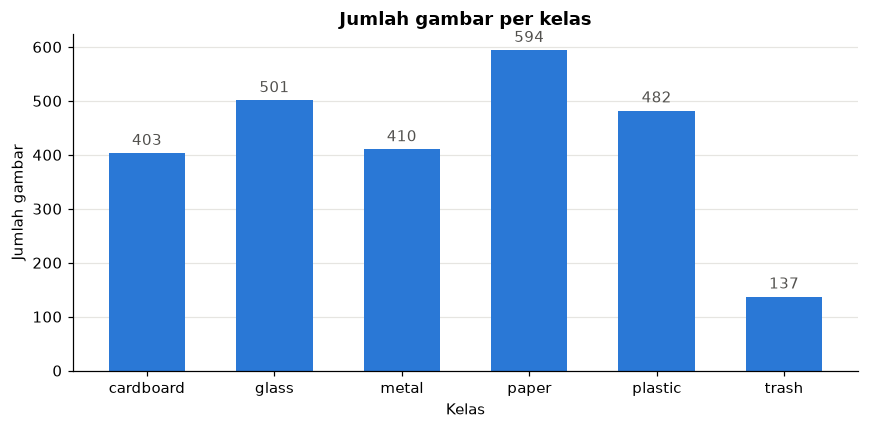

Total gambar: 2527
Kelas terbanyak: paper (594), kelas tersedikit: trash (137)
Rasio imbalance (terbanyak / tersedikit): 4.34


In [2]:
classes = get_classes(DATA_DIR)
all_items = list_images(DATA_DIR)
counts = pd.Series([c for _, c in all_items]).value_counts().reindex(classes)
imbalance_ratio = counts.max() / counts.min()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, padding=3, color=MUTED)
ax.set_title("Jumlah gambar per kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah gambar")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Total gambar: {counts.sum()}")
print(f"Kelas terbanyak: {counts.idxmax()} ({counts.max()}), kelas tersedikit: {counts.idxmin()} ({counts.min()})")
print(f"Rasio imbalance (terbanyak / tersedikit): {imbalance_ratio:.2f}")

Total ada 2.527 gambar. Paper paling banyak (594) dan trash paling sedikit (137), dengan rasio imbalance sekitar **4,3 : 1**. Lima kelas lain cukup seimbang (400 sampai 600), jadi masalah utamanya ada di kelas trash.

**Dampak ke model:** saat training, model lebih sering melihat contoh paper daripada trash, sehingga cenderung "aman" menebak kelas besar. Akibatnya recall trash bisa rendah walaupun akurasi total terlihat bagus. Ini alasan kita memakai macro F1 sebagai metrik utama dan menambahkan *class weights* di bagian 3.

### Contoh gambar per kelas
Melihat gambar secara langsung membantu memahami seberapa sulit tugasnya dan apakah ada pola yang tidak diinginkan (misalnya latar belakang yang berbeda per kelas).

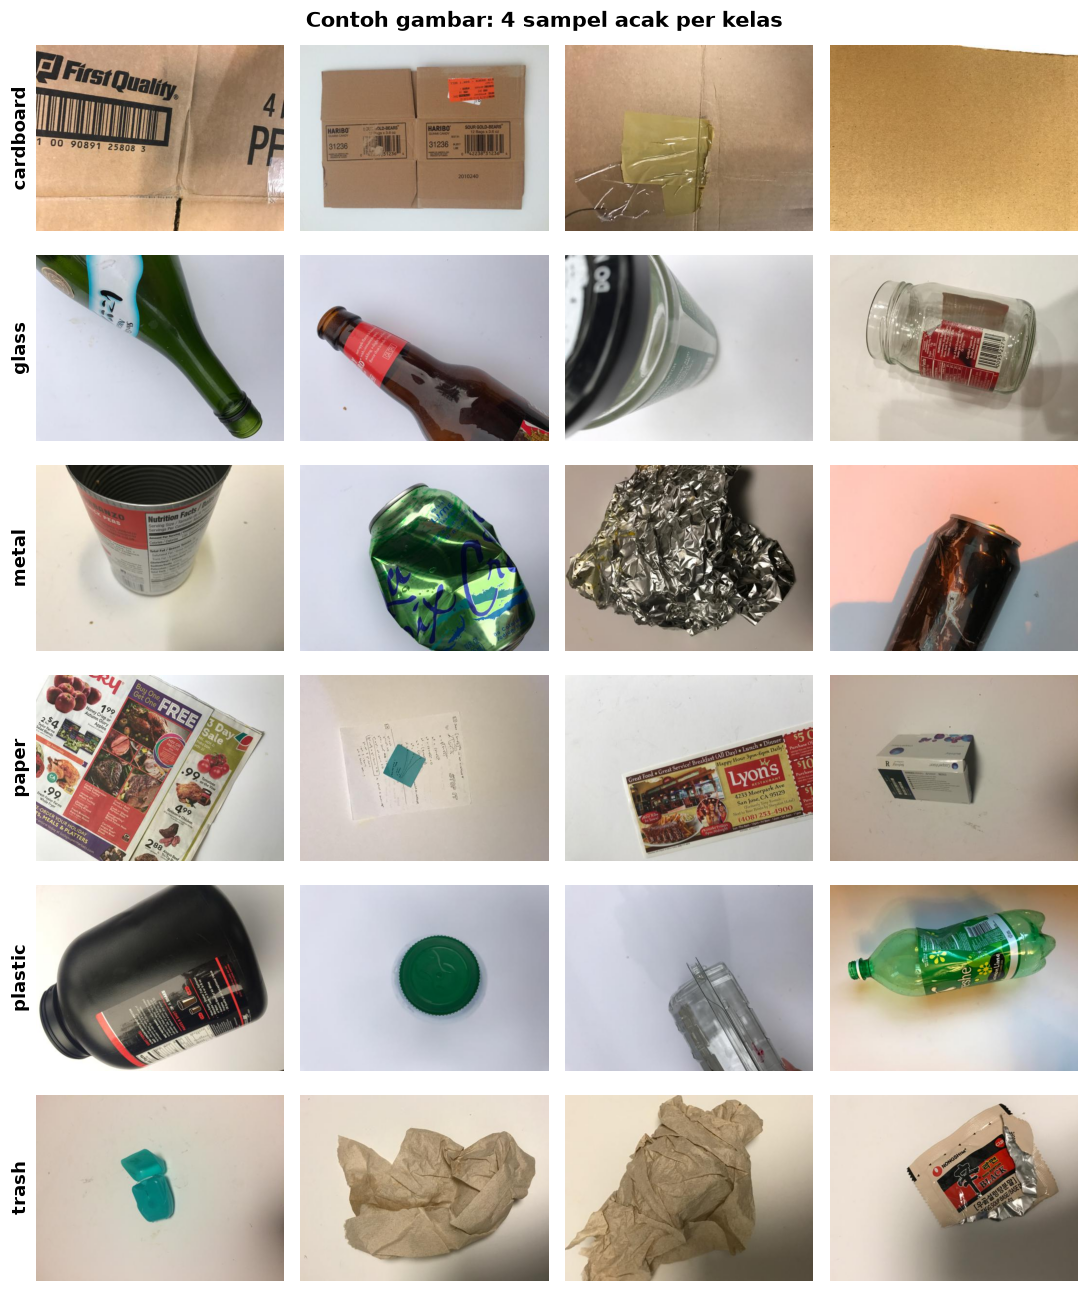

In [3]:
rng = np.random.default_rng(SEED)
n_per_class = 4
fig, axes = plt.subplots(len(classes), n_per_class, figsize=(10, 12))
for r, cls in enumerate(classes):
    cls_items = [p for p, c in all_items if c == cls]
    for k, rel in enumerate(rng.choice(cls_items, n_per_class, replace=False)):
        ax = axes[r, k]
        ax.imshow(Image.open(DATA_DIR / rel))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if k == 0:
            ax.set_ylabel(cls, fontsize=12, fontweight="bold")
fig.suptitle("Contoh gambar: 4 sampel acak per kelas", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Setiap foto berisi satu objek di atas latar belakang polos (putih atau krem) dengan pencahayaan dalam ruangan. Beberapa kelas mirip secara visual: botol plastik bening mirip botol kaca, dan kertas cetak mengilap mirip kardus tipis, jadi kemungkinan besar pasangan ini yang nanti sering tertukar.

### Resolusi gambar
Resolusi yang beragam memengaruhi cara resize dan crop. Kalau ukurannya sangat bervariasi, resize bisa merusak proporsi objek.

In [4]:
sizes = []
for rel, cls in all_items:
    with Image.open(DATA_DIR / rel) as im:
        sizes.append({"kelas": cls, "lebar": im.width, "tinggi": im.height, "format": im.format, "mode": im.mode})
size_df = pd.DataFrame(sizes)
size_df.groupby(["lebar", "tinggi", "format", "mode"]).size().rename("jumlah gambar").reset_index()

,lebar,tinggi,format,mode,jumlah gambar
0,512,384,JPEG,RGB,2527


Semua 2.527 gambar berukuran sama, **512 x 384 piksel** (rasio 4:3), format JPEG, mode RGB. Jadi preprocessing cukup sederhana: resize sisi pendek lalu crop tengah ke 224 x 224 tanpa distorsi, dan tidak perlu konversi format.

### Rata-rata warna per kelas (cek bias background)
Kalau background atau pencahayaan berbeda per kelas, model bisa "curang": belajar mengenali latar belakang, bukan objeknya. Untuk mengeceknya, kita hitung dua hal per gambar:
- **warna rata-rata seluruh gambar**, yang dipengaruhi objek dan background, dan
- **kecerahan bagian tepi gambar** (bingkai selebar sekitar 6% dari tepi), yang sebagian besar berisi background.

Kalau kecerahan tepi sangat berbeda antar kelas, itu tanda ada bias background.

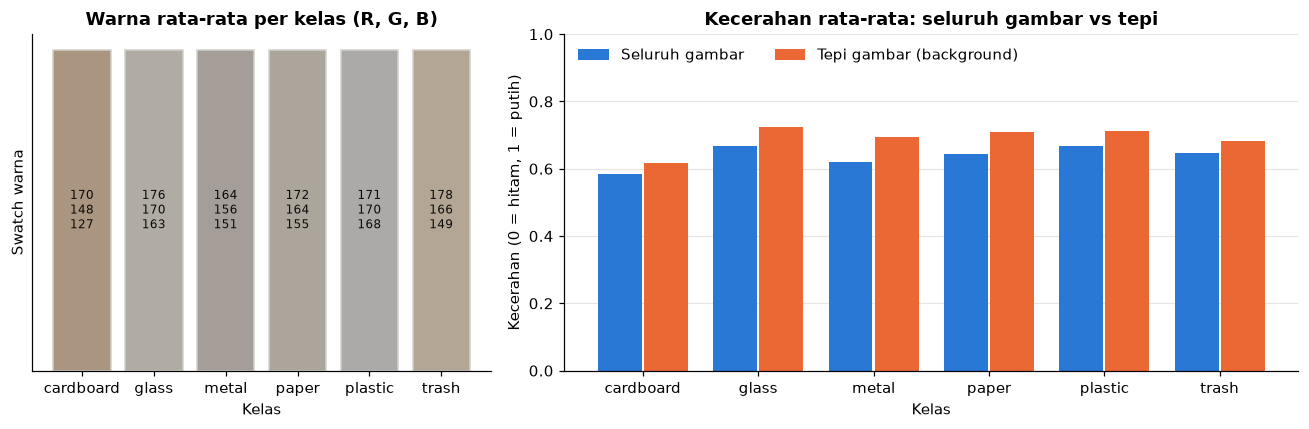

,R,G,B,kecerahan_total,kecerahan_tepi
kelas,,,,,
cardboard,0.667,0.584,0.502,0.584,0.619
glass,0.692,0.669,0.640,0.667,0.724
metal,0.646,0.616,0.596,0.619,0.695
paper,0.675,0.645,0.610,0.643,0.709
plastic,0.671,0.667,0.663,0.667,0.712
trash,0.701,0.651,0.584,0.646,0.684


In [5]:
def color_stats(path, size=(64, 48), border=4):
    arr = np.asarray(Image.open(path).convert("RGB").resize(size), dtype=np.float32) / 255
    edge = np.concatenate([
        arr[:border].reshape(-1, 3), arr[-border:].reshape(-1, 3),
        arr[:, :border].reshape(-1, 3), arr[:, -border:].reshape(-1, 3),
    ])
    r, g, b = arr.reshape(-1, 3).mean(axis=0)
    return r, g, b, arr.mean(), edge.mean()

color_df = pd.DataFrame(
    [(cls, *color_stats(DATA_DIR / rel)) for rel, cls in all_items],
    columns=["kelas", "R", "G", "B", "kecerahan_total", "kecerahan_tepi"],
)
color_mean = color_df.groupby("kelas").mean().reindex(classes)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})

# Kiri: swatch warna rata-rata per kelas (warna di sini adalah data, bukan palet)
ax1.bar(classes, [1] * len(classes), color=color_mean[["R", "G", "B"]].values, edgecolor="#d0cfca", width=0.8)
for i, cls in enumerate(classes):
    r, g, b = color_mean.loc[cls, ["R", "G", "B"]]
    ax1.text(i, 0.5, f"{int(r*255)}\n{int(g*255)}\n{int(b*255)}", ha="center", va="center", fontsize=8, color="#0b0b0b")
ax1.set_title("Warna rata-rata per kelas (R, G, B)")
ax1.set_xlabel("Kelas")
ax1.set_ylabel("Swatch warna")
ax1.set_yticks([]); ax1.grid(False)

# Kanan: kecerahan total vs kecerahan tepi per kelas
x = np.arange(len(classes))
w = 0.38
b1 = ax2.bar(x - w / 2 - 0.01, color_mean["kecerahan_total"], w, color=BLUE, label="Seluruh gambar")
b2 = ax2.bar(x + w / 2 + 0.01, color_mean["kecerahan_tepi"], w, color=ORANGE, label="Tepi gambar (background)")
ax2.set_xticks(x, classes)
ax2.set_ylim(0, 1)
ax2.set_title("Kecerahan rata-rata: seluruh gambar vs tepi")
ax2.set_xlabel("Kelas")
ax2.set_ylabel("Kecerahan (0 = hitam, 1 = putih)")
ax2.grid(axis="x", visible=False)
ax2.legend(loc="upper left", ncol=2, frameon=False)
plt.tight_layout()
plt.show()

color_mean.round(3)

Kecerahan tepi lima kelas mirip, sekitar 0,68 sampai 0,72, jadi latar belakangnya secara umum seragam dan tidak ada kelas yang difoto di latar yang jelas berbeda. Pengecualiannya cardboard: tepinya lebih gelap (0,62) dan warnanya lebih kekuningan (B rata-rata paling rendah) karena kardus sering memenuhi seluruh frame sampai ke tepi. Perbedaan ini berasal dari objeknya sendiri, bukan dari background, tetapi tetap berarti model bisa memakai warna cokelat sebagai petunjuk kuat untuk cardboard dan perlu dicek lagi di tahap evaluasi (Grad-CAM).

### Keterbatasan dataset
Dari eksplorasi di atas, ada beberapa keterbatasan yang perlu dicatat karena memengaruhi seberapa baik model bekerja di dunia nyata:

1. **Background seragam dan pencahayaan dalam ruangan.** Semua foto diambil di atas latar putih atau krem. Di dunia nyata (tempat sampah, TPS, conveyor), latarnya ramai dan kotor, jadi akurasi di lapangan kemungkinan lebih rendah dari akurasi di test set.
2. **Satu objek per gambar, bersih, dan utuh.** Sampah asli sering bertumpuk, basah, kotor, atau hancur.
3. **Ukuran data kecil.** Sekitar 2.500 gambar, dan kelas trash hanya 137 gambar. CNN dari nol akan sulit belajar, sehingga transfer learning dan augmentasi menjadi penting.
4. **Kelas trash sangat beragam.** Isinya campuran bungkus snack, sedotan, plastik kemasan, dan lain-lain, sehingga polanya sulit dipelajari dari sedikit contoh.
5. **Produk bukan khas Indonesia.** Kemasan dan merek berasal dari luar negeri (dataset TrashNet dari Amerika Serikat), jadi bisa ada perbedaan dengan sampah lokal.
6. **Ada gambar duplikat dengan label berbeda** (dibahas di bagian 3).

## 3. Data Preparation

Semua fungsi di bagian ini diimplementasikan di `src/data.py`, supaya bisa dipakai ulang saat training dan evaluasi.

### 3.1 Membersihkan duplikat antar kelas
Kita cari file yang isinya identik (hash MD5 sama) tetapi berada di dua folder kelas berbeda. Gambar seperti ini membingungkan model karena satu foto punya dua label, dan bisa bocor ke train dan test sekaligus.

In [6]:
duplicates = find_cross_class_duplicates(DATA_DIR, all_items)
pd.DataFrame(
    [{"file A": g[0][0], "file B": g[1][0]} for g in duplicates]
)

,file A,file B
0,glass/glass115.jpg,metal/metal91.jpg
1,glass/glass176.jpg,plastic/plastic152.jpg
2,glass/glass389.jpg,plastic/plastic332.jpg


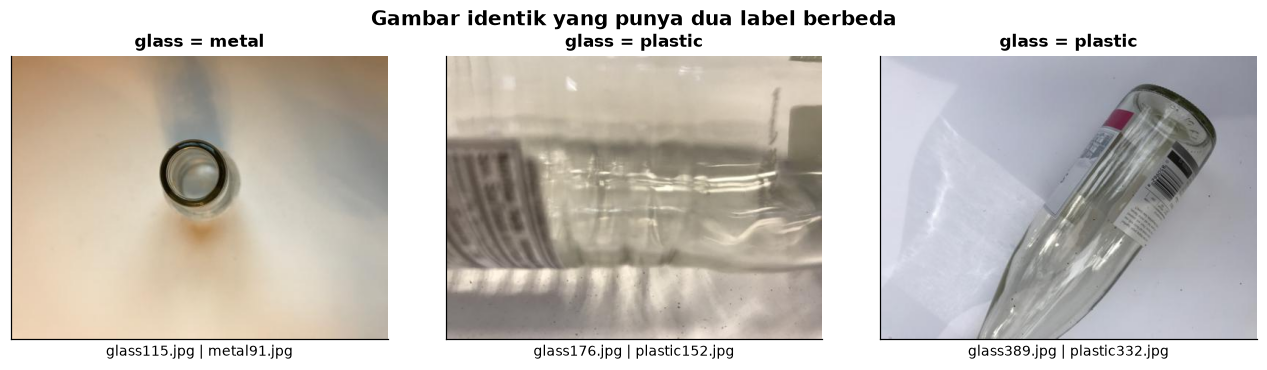

Dibuang: 6 file, sisa: 2521 gambar


In [7]:
fig, axes = plt.subplots(1, len(duplicates), figsize=(12, 3.2))
for ax, group in zip(axes, duplicates):
    ax.imshow(Image.open(DATA_DIR / group[0][0]))
    ax.set_title(" = ".join(c for _, c in group), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_xlabel(" | ".join(Path(p).name for p, _ in group), fontsize=9)
fig.suptitle("Gambar identik yang punya dua label berbeda", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

to_remove = [rel for group in duplicates for rel, _ in group]
items = remove_items(all_items, to_remove)
print(f"Dibuang: {len(to_remove)} file, sisa: {len(items)} gambar")

Ada 3 pasang gambar identik dengan label bertentangan, misalnya leher botol kaca yang juga ada di folder metal. Karena label yang benar tidak bisa dipastikan, kedua salinan dari tiap pasang dibuang (6 file, hanya 0,2% data), sehingga tersisa 2.521 gambar.

### 3.2 Split stratified train / validation / test (70 / 15 / 15)
- **Train** dipakai untuk melatih model.
- **Validation** dipakai untuk memilih model dan hyperparameter (early stopping, learning rate).
- **Test** hanya dipakai **sekali** di akhir, supaya hasilnya jujur dan tidak "tercemar" oleh keputusan kita selama eksperimen.

Split dibuat **stratified**, artinya proporsi tiap kelas sama di ketiga split. Tanpa ini, bisa saja kelas trash yang hanya 137 gambar kebetulan sangat sedikit di test set. Daftar file per split disimpan ke `outputs/splits.json` supaya semua eksperimen memakai split yang sama persis.

In [8]:
splits = make_splits(items, val_size=0.15, test_size=0.15, seed=SEED)
save_splits(splits, classes, OUTPUT_DIR / "splits.json", extra={"removed_duplicates": to_remove})

split_table = pd.DataFrame(
    {name: pd.Series([c for _, c in s]).value_counts() for name, s in splits.items()}
).reindex(classes)
split_table.loc["TOTAL"] = split_table.sum()
split_pct = (split_table.div(split_table.sum(axis=1), axis=0) * 100).round(1).add_suffix(" (%)")
pd.concat([split_table, split_pct], axis=1)

,train,val,test,train (%),val (%),test (%)
cardboard,282,60,61,70.0,14.9,15.1
glass,348,75,75,69.9,15.1,15.1
metal,286,61,62,69.9,14.9,15.2
paper,416,89,89,70.0,15.0,15.0
plastic,336,72,72,70.0,15.0,15.0
trash,96,21,20,70.1,15.3,14.6
TOTAL,1764,378,379,70.0,15.0,15.0


Hasilnya 1.764 gambar train, 378 validation, dan 379 test. Setiap kelas terbagi mendekati 70/15/15, termasuk trash (96/21/20), sehingga semua split punya komposisi kelas yang sama.

### 3.3 Transformasi dan augmentasi
Model pretrained di ImageNet menerima gambar 224 x 224 yang dinormalisasi dengan mean dan std ImageNet, jadi kita pakai format yang sama.

**Transform train (dengan augmentasi):**
- `RandomResizedCrop(224, scale 0,7 sampai 1,0)`: memotong bagian acak lalu resize, seolah foto diambil dari jarak dan posisi berbeda.
- `RandomHorizontalFlip`: sampah tetap sampah walaupun dicerminkan.
- `RandomRotation(15 derajat)`: rotasi kecil, meniru kamera yang agak miring.
- `ColorJitter` ringan: variasi kecerahan, kontras, dan saturasi, meniru pencahayaan yang berbeda. Hue hanya digeser sedikit karena warna adalah ciri penting (kardus cokelat, kaca hijau).

**Transform val/test (tanpa augmentasi):** resize sisi pendek ke 256, center crop 224, lalu normalisasi. Evaluasi harus deterministik supaya hasilnya bisa dibandingkan.

**Kenapa augmentasi penting untuk dataset kecil?** Dengan hanya sekitar 1.700 gambar train, model mudah *menghafal* gambar training (overfitting): akurasi train tinggi tetapi gagal di gambar baru. Augmentasi membuat setiap epoch melihat versi gambar yang sedikit berbeda, sehingga model dipaksa belajar ciri yang benar-benar penting (bentuk, tekstur, material), bukan posisi atau pencahayaan tertentu.

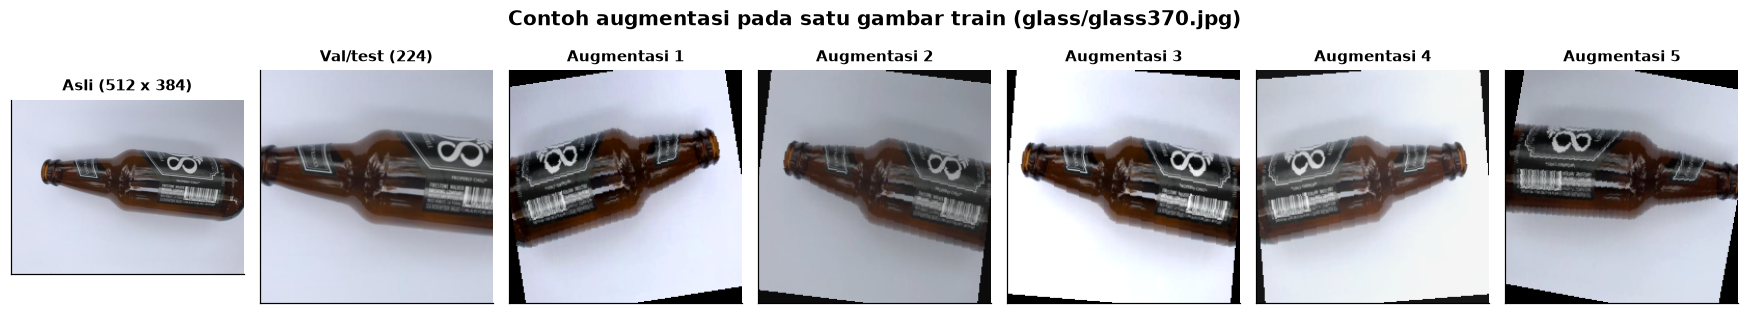

In [9]:
train_tf = get_transforms(train=True)
eval_tf = get_transforms(train=False)
set_seed(SEED)

# Botol kaca dengan objek yang jelas, dipilih dari data train
sample_rel = "glass/glass370.jpg"
assert sample_rel in {rel for rel, _ in splits["train"]}
original = Image.open(DATA_DIR / sample_rel).convert("RGB")
n_aug = 5
fig, axes = plt.subplots(1, n_aug + 2, figsize=(16, 3))
panels = [(original, "Asli (512 x 384)"), (denormalize(eval_tf(original)), "Val/test (224)")]
panels += [(denormalize(train_tf(original)), f"Augmentasi {i+1}") for i in range(n_aug)]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img if isinstance(img, Image.Image) else img.permute(1, 2, 0).numpy())
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f"Contoh augmentasi pada satu gambar train ({sample_rel})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Dari satu foto yang sama, augmentasi menghasilkan variasi posisi, skala, sudut, dan pencahayaan, tetapi objeknya tetap jelas botol kaca, jadi label tidak berubah. Sudut hitam kecil muncul akibat rotasi, dan karena posisinya acak di setiap epoch, model tidak menjadikannya ciri kelas tertentu.

### 3.4 Class weights untuk menangani imbalance
Saat training, loss (kesalahan) dari setiap gambar dikalikan dengan bobot kelasnya. Rumus yang dipakai adalah bobot "balanced":

$$w_c = \frac{N_{total}}{K \times N_c}$$

dengan $N_{total}$ = jumlah gambar train, $K$ = jumlah kelas (6), dan $N_c$ = jumlah gambar kelas $c$. Kelas yang jarang dapat bobot besar, sehingga satu kesalahan pada gambar trash "dihukum" lebih berat daripada satu kesalahan pada paper. Secara total, setiap kelas jadi punya pengaruh yang kira-kira sama ke loss. Bobot dihitung **hanya dari data train** supaya informasi dari val/test tidak bocor.

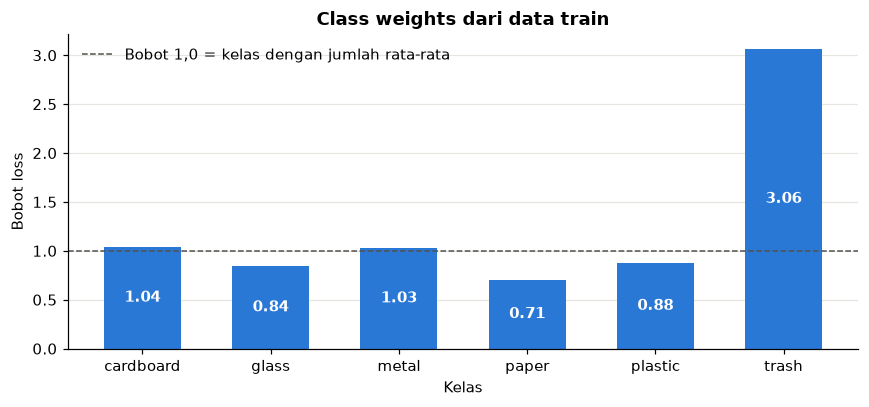

,jumlah train,class weight
cardboard,282,1.043
glass,348,0.845
metal,286,1.028
paper,416,0.707
plastic,336,0.875
trash,96,3.062


In [10]:
class_weights = compute_class_weights(splits["train"], classes)
train_counts = split_table.loc[classes, "train"]
weights_df = pd.DataFrame({"jumlah train": train_counts, "class weight": class_weights.numpy().round(3)})

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(classes, class_weights.numpy(), color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.2f", label_type="center", color="white", fontweight="bold")
ax.axhline(1.0, color=MUTED, linewidth=1, linestyle="--", label="Bobot 1,0 = kelas dengan jumlah rata-rata")
ax.legend(loc="upper left", frameon=False)
ax.set_title("Class weights dari data train")
ax.set_xlabel("Kelas")
ax.set_ylabel("Bobot loss")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

weights_df

Trash mendapat bobot sekitar 3,06, artinya satu kesalahan pada gambar trash dihitung kira-kira 3 kali lebih berat dari rata-rata. Paper, kelas terbesar, mendapat bobot terkecil (0,71). Bobot ini nanti dipasang di `CrossEntropyLoss(weight=class_weights)` saat training.

### 3.5 DataLoader
DataLoader mengambil gambar per batch, menerapkan transform, lalu mengirimnya ke model. Batch size 32 dengan gambar 224 x 224 aman untuk VRAM 8 GB, bahkan untuk model yang cukup besar. `num_workers=0` dipakai karena DataLoader multi-proses sering bermasalah di notebook Windows. Hanya data train yang diacak (shuffle), dengan generator ber-seed supaya urutannya bisa diulang.

In [11]:
loaders = make_dataloaders(DATA_DIR, splits, classes, batch_size=BATCH_SIZE, num_workers=0)
images, labels = next(iter(loaders["train"]))

pd.DataFrame({
    name: {"jumlah gambar": len(dl.dataset), "jumlah batch": len(dl), "shuffle": name == "train"}
    for name, dl in loaders.items()
}).T

,jumlah gambar,jumlah batch,shuffle
train,1764,56,True
val,378,12,False
test,379,12,False


In [12]:
print("Bentuk batch gambar:", tuple(images.shape), "| tipe:", images.dtype)
print("Bentuk batch label :", tuple(labels.shape))
print(f"Rentang nilai piksel setelah normalisasi: {images.min():.2f} sampai {images.max():.2f}")
print("Label di batch pertama:", pd.Series([classes[i] for i in labels.tolist()]).value_counts().to_dict())

Bentuk batch gambar: (32, 3, 224, 224) | tipe: torch.float32
Bentuk batch label : (32,)
Rentang nilai piksel setelah normalisasi: -2.12 sampai 2.64
Label di batch pertama: {'paper': 8, 'plastic': 8, 'glass': 7, 'metal': 5, 'cardboard': 4}


Satu batch berisi 32 gambar berukuran 3 x 224 x 224 dengan label bilangan bulat 0 sampai 5, sesuai format input CNN di PyTorch. Nilai piksel sudah dinormalisasi (sekitar -2 sampai 2,6), dan batch pertama berisi campuran kelas karena data train diacak.

**Ringkasan Data Preparation:** data sudah bersih dari duplikat, terbagi stratified 70/15/15 (disimpan di `outputs/splits.json`), punya augmentasi untuk train, class weights untuk menangani imbalance, dan DataLoader yang siap dipakai. Tahap berikutnya adalah **Modeling**.

## 4. Modeling

Kita menjalankan tiga eksperimen untuk menjawab pertanyaan bisnis nomor 2 (seberapa besar keuntungan transfer learning) dan nomor 4 (model mana yang paling cocok untuk aplikasi nyata):

| Eksperimen | Model | Ide utama |
|---|---|---|
| A | CNN sederhana dari nol | Baseline: seberapa jauh kita bisa tanpa pengetahuan awal |
| B | MobileNetV2 pretrained | Model ringan yang dirancang untuk HP dan browser |
| C | ResNet50 pretrained | Model besar dan kuat, sebagai pembanding "batas atas" |

**Pengaturan yang sama untuk semua eksperimen** (supaya perbandingannya adil):
- **Loss:** `CrossEntropyLoss` dengan class weights dari bagian 3.4, supaya kelas trash tidak diabaikan.
- **Optimizer:** AdamW, yaitu Adam dengan *weight decay* 1e-4. Adam menyesuaikan langkah belajar untuk setiap parameter sehingga cepat konvergen, dan weight decay mencegah bobot tumbuh terlalu besar (mengurangi overfitting).
- **Learning rate scheduler:** `ReduceLROnPlateau`. Kalau val loss tidak membaik selama 2 epoch, learning rate dipotong setengah. Ibaratnya, saat sudah dekat tujuan, langkahnya diperkecil supaya tidak melewati titik terbaik.
- **Early stopping:** training berhenti kalau val loss tidak membaik selama 5 epoch berturut-turut, lalu bobot dari epoch terbaik yang dipakai. Ini mencegah overfitting dan menghemat waktu.
- **Checkpoint:** bobot terbaik (val loss terendah) disimpan ke `checkpoints/`.
- **Mixed precision (`torch.amp`):** sebagian besar perhitungan memakai float16 sehingga training lebih cepat dan hemat VRAM, dengan hasil yang praktis sama.

Semua pemilihan model di bagian ini memakai **validation set**. Test set belum disentuh.

In [13]:
import time

from torch import nn
from torch.optim.lr_scheduler import ReduceLROnPlateau

from src.data import load_splits
from src.models import (
    SimpleCNN, build_mobilenet_v2, build_resnet50, count_parameters, freeze_backbone,
    measure_latency_ms, state_dict_size_mb, unfreeze_last_blocks,
)
from src.train import evaluate, fit, macro_f1, plot_history

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)

# Split dibaca dari file supaya identik dengan bagian 3 (dan dengan eksperimen di masa depan)
splits, classes = load_splits(OUTPUT_DIR / "splits.json")
class_weights = compute_class_weights(splits["train"], classes)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

# Coba DataLoader multi-proses (lebih cepat), kalau gagal di Windows pakai num_workers=0
try:
    loaders = make_dataloaders(DATA_DIR, splits, classes, batch_size=BATCH_SIZE, num_workers=4)
    next(iter(loaders["val"]))
    print("DataLoader: num_workers=4 (persistent)")
except Exception as e:
    print("num_workers=4 gagal, pakai 0:", repr(e))
    loaders = make_dataloaders(DATA_DIR, splits, classes, batch_size=BATCH_SIZE, num_workers=0)

results, histories = {}, {}


def trainable_params(model):
    return [p for p in model.parameters() if p.requires_grad]


def make_optimizer(model, lr):
    optimizer = torch.optim.AdamW(trainable_params(model), lr=lr, weight_decay=1e-4)
    return optimizer, ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)


def show_params(model, label):
    total, trainable = count_parameters(model)
    print(f"{label}: total {total:,} parameter, dilatih {trainable:,} ({trainable / total:.1%})")
    return total, trainable


def finish_experiment(key, name, model, history, vram_gb):
    """Hitung metrik validation dan ringkasan eksperimen dari bobot terbaik."""
    val_loss, val_acc, y_true, y_pred = evaluate(model, loaders["val"], criterion, device)
    total, _ = count_parameters(model)
    results[key] = {
        "model": name,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": macro_f1(y_true, y_pred),
        "total_params": total,
        "size_mb": state_dict_size_mb(model),
        "epochs": len(history),
        "train_time_min": sum(h["epoch_time"] for h in history) / 60,
        "vram_peak_gb": vram_gb,
        "cpu_latency_ms": measure_latency_ms(model),
    }
    model.to(device)
    histories[key] = history
    r = results[key]
    print(f"{name}: val acc {r['val_accuracy']:.4f} | val macro F1 {r['val_macro_f1']:.4f} | "
          f"{r['epochs']} epoch | waktu {r['train_time_min']:.1f} menit | VRAM puncak {vram_gb:.2f} GB")

DataLoader: num_workers=4 (persistent)


Loader, loss, dan fungsi bantu sudah siap. Semua eksperimen memakai split, class weights, dan pengaturan training yang sama, jadi perbedaan hasil murni berasal dari arsitektur dan strategi training.

### 4.1 Eksperimen A: CNN sederhana dari nol

Arsitekturnya 4 blok konvolusi. Setiap blok berisi dua lapisan konvolusi 3 x 3, BatchNorm (menstabilkan training), ReLU, dan max pooling (memperkecil ukuran gambar setengahnya). Jumlah filter naik 32, 64, 128, 256: blok awal menangkap pola sederhana (garis, warna), blok akhir menangkap pola yang lebih kompleks (tekstur, bentuk). Di ujungnya ada global average pooling, dropout 0,3, lalu layer linear untuk 6 kelas.

Semua bobot dimulai dari angka acak, jadi model harus belajar segalanya hanya dari sekitar 1.700 gambar. Learning rate 1e-3, maksimal 30 epoch.

In [14]:
set_seed(SEED)
model_a = SimpleCNN(num_classes=len(classes)).to(device)
show_params(model_a, "CNN dari nol")

torch.cuda.reset_peak_memory_stats()
optimizer, scheduler = make_optimizer(model_a, lr=1e-3)
hist_a, _ = fit(model_a, loaders, criterion, optimizer, scheduler, device, epochs=30,
                checkpoint_path=CKPT_DIR / "a_simple_cnn.pt", patience=5, stage="scratch")
finish_experiment("A", "CNN dari nol", model_a, hist_a, torch.cuda.max_memory_allocated() / 1024**3)

CNN dari nol: total 1,174,758 parameter, dilatih 1,174,758 (100.0%)


[scratch] epoch 01 | train loss 1.507 acc 0.393 | val loss 1.499 acc 0.421 | lr 1e-03 | 10.4s *


[scratch] epoch 02 | train loss 1.373 acc 0.444 | val loss 1.298 acc 0.452 | lr 1e-03 | 4.6s *


[scratch] epoch 03 | train loss 1.341 acc 0.465 | val loss 1.513 acc 0.444 | lr 1e-03 | 4.6s


[scratch] epoch 04 | train loss 1.343 acc 0.461 | val loss 1.297 acc 0.474 | lr 1e-03 | 4.6s *


[scratch] epoch 05 | train loss 1.290 acc 0.480 | val loss 1.165 acc 0.526 | lr 1e-03 | 4.6s *


... (20 outputs left out)

[scratch] epoch 26 | train loss 0.896 acc 0.666 | val loss 0.949 acc 0.646 | lr 3e-04 | 4.5s


[scratch] epoch 27 | train loss 0.850 acc 0.701 | val loss 0.842 acc 0.664 | lr 1e-04 | 4.5s


[scratch] epoch 28 | train loss 0.816 acc 0.721 | val loss 0.829 acc 0.677 | lr 1e-04 | 4.6s
[scratch] 28 epoch, stop karena early stopping. Val loss terbaik tahap ini: 0.8194 (epoch 23), checkpoint diperbarui.


CNN dari nol: val acc 0.7090 | val macro F1 0.6567 | 28 epoch | waktu 2.2 menit | VRAM puncak 1.02 GB


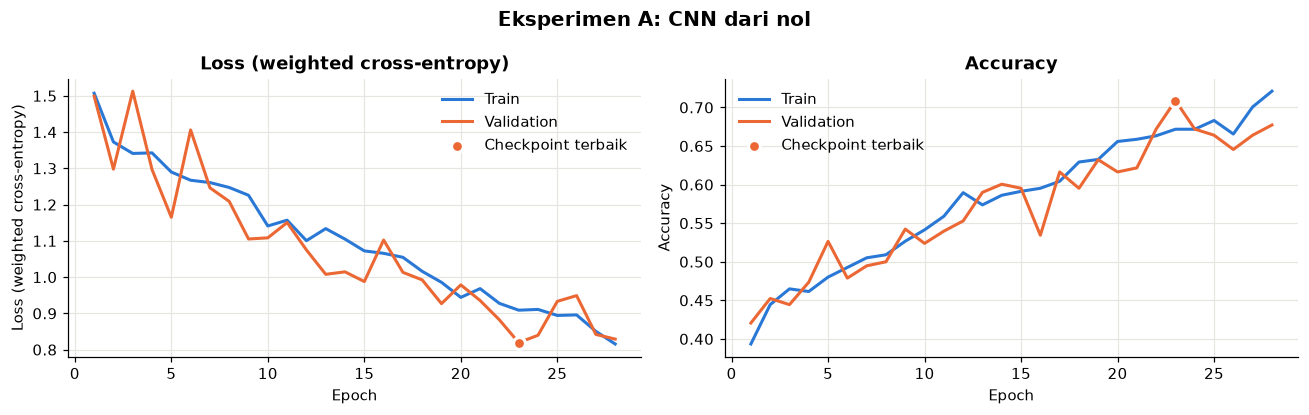

In [15]:
plot_history(hist_a, "Eksperimen A: CNN dari nol")

Kurva train dan validation bergerak berdekatan sepanjang training (di epoch terakhir akurasi train 0,72 dan val 0,68), jadi model ini **tidak overfitting, justru underfitting**: model belum mampu mempelajari ciri yang membedakan material. Akurasi train sempat lebih rendah dari val di awal karena augmentasi dan dropout hanya aktif saat training. Checkpoint terbaik ada di epoch 23 dengan val accuracy 0,709 dan val macro F1 hanya **0,657**, jauh di bawah target 0,85. Kurva validation juga naik-turun tajam, tanda model belum stabil. Kesimpulannya, dengan sekitar 1.700 gambar, belajar dari nol tidak cukup.

### 4.2 Eksperimen B: MobileNetV2 pretrained (dua tahap)

**Transfer learning** berarti memakai model yang sudah dilatih di ImageNet (1,2 juta foto, 1.000 kelas). Model ini sudah "tahu" cara melihat tepi, tekstur, kilap, dan bentuk, sehingga kita tinggal mengajarinya menggabungkan pengetahuan itu untuk 6 jenis sampah. MobileNetV2 dipilih karena dirancang untuk perangkat dengan sumber daya terbatas (HP, browser): parameternya sekitar 2,2 juta dan ukurannya sekitar 9 MB.

**Kenapa dibagi dua tahap?**
1. **Tahap 1, feature extraction:** semua layer backbone dibekukan (tidak dilatih), hanya classifier baru untuk 6 kelas yang dilatih dengan learning rate 1e-3. Classifier baru awalnya berisi bobot acak. Kalau seluruh model langsung dilatih, gradien besar dari classifier acak ini akan "merusak" fitur pretrained yang berharga. Jadi classifier dilatih dulu sampai masuk akal.
2. **Tahap 2, fine-tuning:** 5 blok terakhir backbone dibuka dan dilatih ulang bersama classifier. Blok akhir berisi fitur yang spesifik untuk ImageNet (misalnya pola wajah anjing), sehingga perlu disesuaikan ke tekstur sampah. Blok awal (tepi dan warna) bersifat umum dan tetap dibekukan.

**Kenapa learning rate fine-tuning harus kecil (1e-4, 10 kali lebih kecil)?** Bobot pretrained sudah berada di titik yang bagus. Learning rate besar akan menggesernya terlalu jauh sehingga pengetahuan dari ImageNet hilang (*catastrophic forgetting*), apalagi datanya sedikit. Learning rate kecil hanya "menyetel halus" bobot tersebut.

Catatan teknis: BatchNorm di layer yang dibekukan tetap memakai statistik ImageNet (mode eval), supaya fitur pretrained tidak bergeser.

In [16]:
set_seed(SEED)
model_b = build_mobilenet_v2(num_classes=len(classes)).to(device)
ckpt_b = CKPT_DIR / "b_mobilenet_v2.pt"
torch.cuda.reset_peak_memory_stats()

# Tahap 1: feature extraction
freeze_backbone(model_b)
show_params(model_b, "MobileNetV2 tahap 1")
optimizer, scheduler = make_optimizer(model_b, lr=1e-3)
hist_b1, best_b = fit(model_b, loaders, criterion, optimizer, scheduler, device, epochs=10,
                      checkpoint_path=ckpt_b, patience=5, stage="feature_extraction")

# Tahap 2: fine-tuning 5 blok terakhir
unfreeze_last_blocks(model_b, n_blocks=5)
show_params(model_b, "MobileNetV2 tahap 2")
optimizer, scheduler = make_optimizer(model_b, lr=1e-4)
hist_b2, _ = fit(model_b, loaders, criterion, optimizer, scheduler, device, epochs=20,
                 checkpoint_path=ckpt_b, patience=5, stage="fine_tuning", best_val_loss=best_b)

finish_experiment("B", "MobileNetV2", model_b, hist_b1 + hist_b2, torch.cuda.max_memory_allocated() / 1024**3)

MobileNetV2 tahap 1: total 2,231,558 parameter, dilatih 7,686 (0.3%)


[feature_extraction] epoch 01 | train loss 1.288 acc 0.635 | val loss 0.944 acc 0.741 | lr 1e-03 | 4.1s *


[feature_extraction] epoch 02 | train loss 0.835 acc 0.756 | val loss 0.777 acc 0.746 | lr 1e-03 | 3.5s *


[feature_extraction] epoch 03 | train loss 0.687 acc 0.806 | val loss 0.691 acc 0.770 | lr 1e-03 | 3.6s *


[feature_extraction] epoch 04 | train loss 0.592 acc 0.819 | val loss 0.624 acc 0.796 | lr 1e-03 | 3.5s *


[feature_extraction] epoch 05 | train loss 0.560 acc 0.824 | val loss 0.590 acc 0.807 | lr 1e-03 | 3.5s *


... (16 outputs left out)

[fine_tuning] epoch 12 | train loss 0.064 acc 0.981 | val loss 0.331 acc 0.873 | lr 1e-04 | 3.5s


[fine_tuning] epoch 13 | train loss 0.053 acc 0.990 | val loss 0.329 acc 0.870 | lr 5e-05 | 3.5s


[fine_tuning] epoch 14 | train loss 0.055 acc 0.987 | val loss 0.325 acc 0.876 | lr 5e-05 | 3.4s
[fine_tuning] 14 epoch, stop karena early stopping. Val loss terbaik tahap ini: 0.3251 (epoch 9), checkpoint diperbarui.


MobileNetV2: val acc 0.8862 | val macro F1 0.8807 | 24 epoch | waktu 1.4 menit | VRAM puncak 0.23 GB


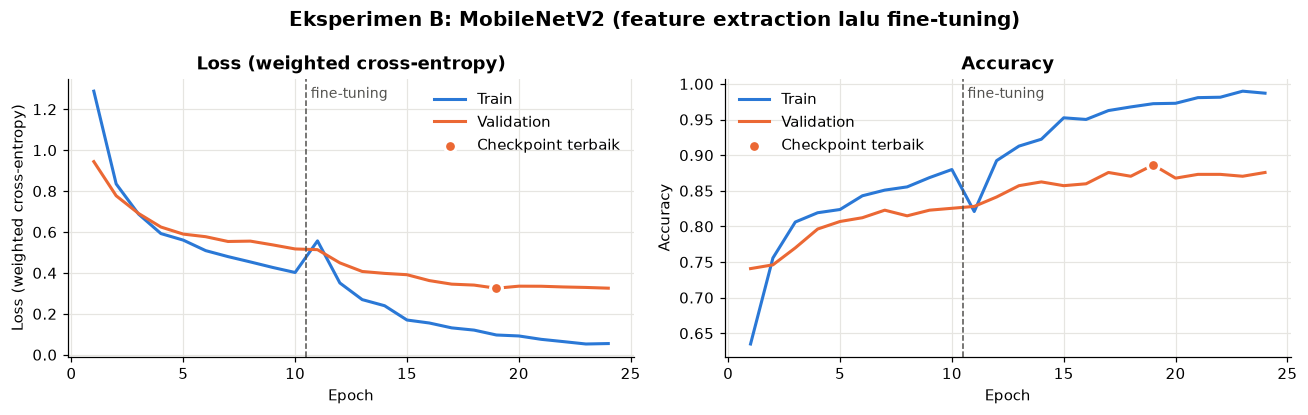

In [17]:
plot_history(hist_b1 + hist_b2, "Eksperimen B: MobileNetV2 (feature extraction lalu fine-tuning)")

Tahap 1 saja (hanya 7.686 parameter yang dilatih, 0,3% dari model) sudah mencapai val accuracy 0,825 dalam 10 epoch, lebih tinggi dari CNN dari nol setelah 28 epoch. Val loss masih turun pelan saat tahap 1 berakhir, tetapi itu tidak masalah karena tujuan tahap 1 hanya menyiapkan classifier yang masuk akal sebelum fine-tuning. Fine-tuning menurunkan val loss dari 0,517 ke **0,325** (epoch 19 secara total) dengan val accuracy 0,886. Lonjakan kecil train loss di awal fine-tuning wajar, karena layer yang baru dibuka (termasuk BatchNorm-nya) mulai menyesuaikan diri.

Setelah epoch 19, akurasi train terus naik mendekati 0,99 sementara val tertahan di sekitar 0,87. Ini **overfitting ringan** (selisih sekitar 11 poin): model mulai menghafal data train. Early stopping menghentikan training 5 epoch kemudian dan memakai checkpoint terbaik, sehingga overfitting ini tidak ikut terbawa.

### 4.3 Eksperimen C: ResNet50 pretrained (dua tahap)

ResNet50 adalah arsitektur yang jauh lebih besar (sekitar 23,5 juta parameter, sekitar 90 MB). Ciri khasnya adalah *skip connection*: input setiap blok ditambahkan langsung ke outputnya, sehingga jaringan yang sangat dalam tetap bisa dilatih. Eksperimen ini menjawab pertanyaan: apakah model yang 10 kali lebih besar memberikan akurasi yang sepadan dengan ukurannya?

Strateginya sama dengan eksperimen B: tahap 1 hanya melatih classifier (learning rate 1e-3), lalu tahap 2 membuka blok terakhir (`layer4`, sekitar 15 juta parameter) dengan learning rate 1e-4.

In [18]:
set_seed(SEED)
model_c = build_resnet50(num_classes=len(classes)).to(device)
ckpt_c = CKPT_DIR / "c_resnet50.pt"
torch.cuda.reset_peak_memory_stats()

# Tahap 1: feature extraction
freeze_backbone(model_c)
show_params(model_c, "ResNet50 tahap 1")
optimizer, scheduler = make_optimizer(model_c, lr=1e-3)
hist_c1, best_c = fit(model_c, loaders, criterion, optimizer, scheduler, device, epochs=10,
                      checkpoint_path=ckpt_c, patience=5, stage="feature_extraction")

# Tahap 2: fine-tuning layer4
unfreeze_last_blocks(model_c, n_blocks=1)
show_params(model_c, "ResNet50 tahap 2")
optimizer, scheduler = make_optimizer(model_c, lr=1e-4)
hist_c2, _ = fit(model_c, loaders, criterion, optimizer, scheduler, device, epochs=20,
                 checkpoint_path=ckpt_c, patience=5, stage="fine_tuning", best_val_loss=best_c)

finish_experiment("C", "ResNet50", model_c, hist_c1 + hist_c2, torch.cuda.max_memory_allocated() / 1024**3)

ResNet50 tahap 1: total 23,520,326 parameter, dilatih 12,294 (0.1%)


[feature_extraction] epoch 01 | train loss 1.219 acc 0.645 | val loss 0.839 acc 0.770 | lr 1e-03 | 3.5s *


[feature_extraction] epoch 02 | train loss 0.704 acc 0.825 | val loss 0.675 acc 0.796 | lr 1e-03 | 3.6s *


[feature_extraction] epoch 03 | train loss 0.545 acc 0.850 | val loss 0.589 acc 0.815 | lr 1e-03 | 3.5s *


[feature_extraction] epoch 04 | train loss 0.477 acc 0.867 | val loss 0.537 acc 0.825 | lr 1e-03 | 3.5s *


[feature_extraction] epoch 05 | train loss 0.430 acc 0.878 | val loss 0.517 acc 0.831 | lr 1e-03 | 3.5s *


... (12 outputs left out)

[fine_tuning] epoch 08 | train loss 0.022 acc 0.994 | val loss 0.335 acc 0.897 | lr 1e-04 | 3.6s


[fine_tuning] epoch 09 | train loss 0.015 acc 0.997 | val loss 0.340 acc 0.899 | lr 5e-05 | 3.6s


[fine_tuning] epoch 10 | train loss 0.011 acc 0.999 | val loss 0.333 acc 0.910 | lr 5e-05 | 3.6s
[fine_tuning] 10 epoch, stop karena early stopping. Val loss terbaik tahap ini: 0.3034 (epoch 5), checkpoint diperbarui.


ResNet50: val acc 0.8915 | val macro F1 0.8790 | 20 epoch | waktu 1.2 menit | VRAM puncak 0.49 GB


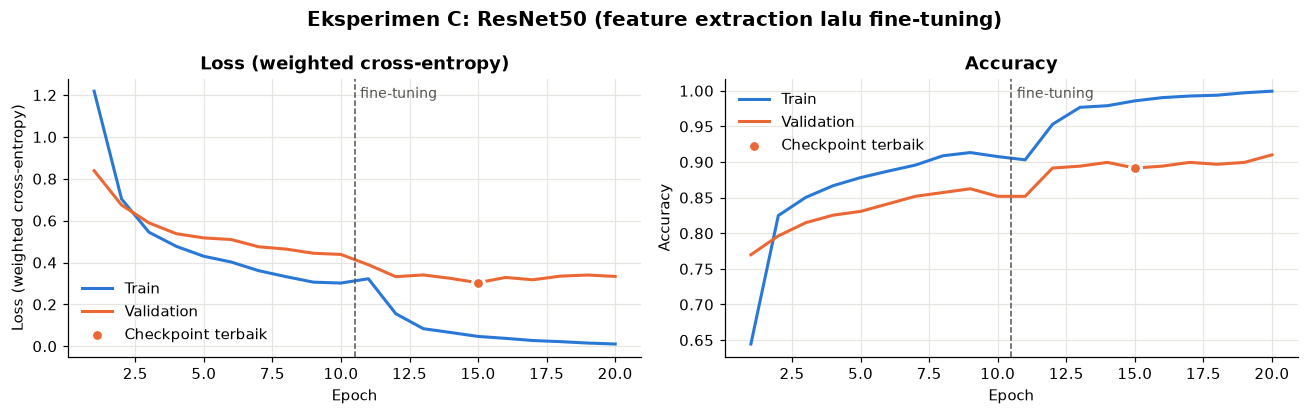

In [19]:
plot_history(hist_c1 + hist_c2, "Eksperimen C: ResNet50 (feature extraction lalu fine-tuning)")

ResNet50 sudah lebih kuat sejak tahap 1 (val loss 0,439 dan val accuracy 0,852, dibanding 0,517 dan 0,825 pada MobileNetV2) karena fiturnya lebih kaya. Fine-tuning menurunkan val loss ke **0,303** di epoch 15 secara total. Namun overfitting paling jelas terlihat di sini: akurasi train mencapai 0,999 dan train loss hampir 0, sementara val loss justru naik lagi setelah epoch 15. Dengan sekitar 15 juta parameter yang dilatih dan hanya 1.764 gambar, model sangat mudah menghafal data train, dan early stopping kembali mencegah bobot yang overfit terpakai.

### 4.4 Perbandingan model (validation set)

Tabel di bawah membandingkan ketiga model dengan bobot terbaiknya. Selain performa, kita juga melihat ukuran file dan kecepatan, karena model akan dijalankan langsung di browser pengguna: file besar berarti waktu unduh lama, dan model berat berarti prediksi lambat di laptop atau HP biasa.

- **Ukuran file:** ukuran bobot float32, mendekati ukuran file ONNX yang nanti diunduh browser.
- **Latensi CPU:** rata-rata waktu memproses satu gambar di CPU laptop ini (tanpa GPU), sebagai gambaran kasar kecepatan di browser.
- **VRAM puncak:** memori GPU terbesar yang dipakai tensor PyTorch selama training.

In [20]:
comparison = pd.DataFrame(results).T[[
    "model", "val_accuracy", "val_macro_f1", "total_params", "size_mb",
    "cpu_latency_ms", "epochs", "train_time_min", "vram_peak_gb",
]]
comparison.columns = [
    "Model", "Val accuracy", "Val macro F1", "Parameter", "Ukuran (MB)",
    "Latensi CPU (ms)", "Epoch", "Waktu training (menit)", "VRAM puncak (GB)",
]
comparison.style.format({
    "Val accuracy": "{:.4f}", "Val macro F1": "{:.4f}", "Parameter": "{:,}",
    "Ukuran (MB)": "{:.1f}", "Latensi CPU (ms)": "{:.1f}", "Waktu training (menit)": "{:.1f}",
    "VRAM puncak (GB)": "{:.2f}",
})

,Model,Val accuracy,Val macro F1,Parameter,Ukuran (MB),Latensi CPU (ms),Epoch,Waktu training (menit),VRAM puncak (GB)
A,CNN dari nol,0.7090,0.6567,"1,174,758",4.5,13.6,28,2.2,1.02
B,MobileNetV2,0.8862,0.8807,"2,231,558",8.7,10.7,24,1.4,0.23
C,ResNet50,0.8915,0.8790,"23,520,326",90.0,32.1,20,1.2,0.49


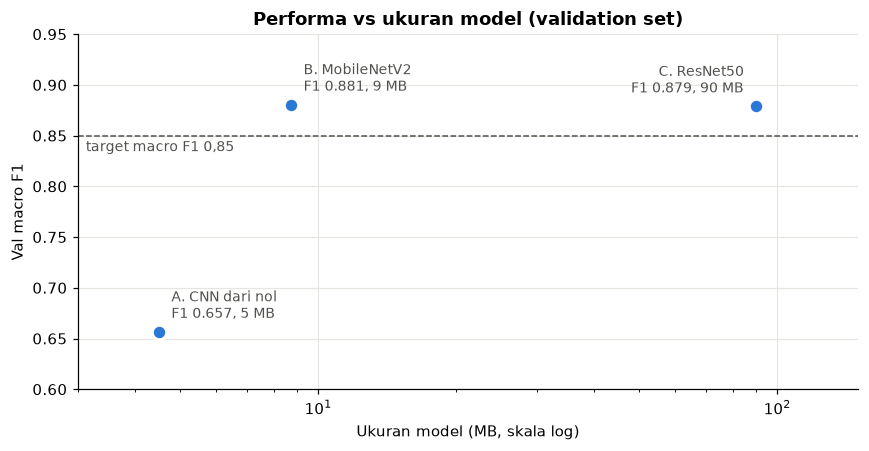

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
# Posisi label diatur per titik supaya tidak saling menimpa
label_pos = {"A": ((8, 6), "left", "bottom"), "B": ((8, 6), "left", "bottom"), "C": ((-8, 6), "right", "bottom")}
for key, r in results.items():
    ax.scatter(r["size_mb"], r["val_macro_f1"], s=90, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
    offset, ha, va = label_pos[key]
    ax.annotate(f"{key}. {r['model']}\nF1 {r['val_macro_f1']:.3f}, {r['size_mb']:.0f} MB",
                (r["size_mb"], r["val_macro_f1"]), xytext=offset, textcoords="offset points",
                fontsize=9, color=MUTED, ha=ha, va=va)
ax.axhline(0.85, color=MUTED, linestyle="--", linewidth=1)
ax.text(0.01, 0.845, "target macro F1 0,85", transform=ax.get_yaxis_transform(), ha="left",
        va="top", fontsize=9, color=MUTED)
ax.set_xscale("log")
ax.set_xlim(3, 150)
ax.set_ylim(0.6, 0.95)
ax.set_xlabel("Ukuran model (MB, skala log)")
ax.set_ylabel("Val macro F1")
ax.set_title("Performa vs ukuran model (validation set)")
plt.tight_layout()
plt.show()

Kedua model transfer learning melampaui target macro F1 0,85 di validation, sedangkan CNN dari nol tertinggal sekitar 22 poin (0,657 vs 0,881). Ini menjawab pertanyaan bisnis nomor 2: **transfer learning memberi lompatan performa yang sangat besar**, bahkan dengan waktu training lebih singkat (sekitar 1 menit vs 2,1 menit), karena model tidak perlu belajar melihat dari nol.

MobileNetV2 dan ResNet50 praktis setara: macro F1 0,881 vs 0,879, accuracy 0,886 vs 0,892. Dengan 378 gambar validation, selisih 0,5% accuracy hanya sekitar 2 gambar. Padahal ResNet50 **10 kali lebih besar** (90 MB vs 9 MB) dan **beberapa kali lebih lambat** di CPU (lihat kolom latensi; angka pastinya sedikit berubah setiap kali diukur karena bergantung pada beban CPU).

### 4.5 Memilih model terbaik

Aturan pemilihan dibuat eksplisit supaya tidak subjektif:
1. Ambil model dengan val macro F1 tertinggi.
2. Kalau ada model yang **lebih kecil** dengan selisih macro F1 **maksimal 0,02 (2 poin persen)**, pilih model yang lebih kecil, karena untuk aplikasi di browser, ukuran dan kecepatan sangat berpengaruh ke pengalaman pengguna, sementara selisih 2 poin hampir tidak terasa.

In [22]:
F1_TOLERANCE = 0.02
best_key = max(results, key=lambda k: results[k]["val_macro_f1"])
candidates = [k for k in results if results[best_key]["val_macro_f1"] - results[k]["val_macro_f1"] <= F1_TOLERANCE]
selected_key = min(candidates, key=lambda k: results[k]["size_mb"])

print(f"F1 tertinggi : {results[best_key]['model']} ({results[best_key]['val_macro_f1']:.4f})")
print(f"Kandidat (selisih <= {F1_TOLERANCE}): {[results[k]['model'] for k in candidates]}")
print(f"Model terpilih: {results[selected_key]['model']}")

ckpt_paths = {"A": "checkpoints/a_simple_cnn.pt", "B": "checkpoints/b_mobilenet_v2.pt", "C": "checkpoints/c_resnet50.pt"}
payload = {
    "seed": SEED,
    "classes": classes,
    "selection_rule": f"macro F1 tertinggi di validation; pilih model lebih kecil jika selisih <= {F1_TOLERANCE}",
    "selected": {"key": selected_key, "model": results[selected_key]["model"], "checkpoint": ckpt_paths[selected_key]},
    "experiments": {
        k: {"summary": results[k], "checkpoint": ckpt_paths[k], "history": histories[k]} for k in results
    },
}
(OUTPUT_DIR / "training_history.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("History disimpan ke outputs/training_history.json")

F1 tertinggi : MobileNetV2 (0.8807)
Kandidat (selisih <= 0.02): ['MobileNetV2', 'ResNet50']
Model terpilih: MobileNetV2
History disimpan ke outputs/training_history.json


**Model terpilih: MobileNetV2.** Macro F1-nya tertinggi (0,881) dan ukurannya paling kecil di antara model yang lolos target. Untuk website demo, ini berarti:
- **Ukuran sekitar 9 MB**, cepat diunduh bahkan lewat jaringan seluler dan jauh di bawah batas 30 MB.
- **Inferensi hanya belasan milidetik per gambar di CPU.** Di browser (ONNX Runtime Web) waktunya akan lebih lama, tetapi masih jauh di bawah target 1 detik.

ResNet50 tidak memberikan keuntungan yang sepadan dengan ukurannya yang 10 kali lebih besar. Ini juga menjawab pertanyaan bisnis nomor 4.

**Catatan penting:** angka di atas berasal dari validation set, yang juga dipakai untuk early stopping dan pemilihan model, sehingga cenderung sedikit optimistis. Performa yang sebenarnya akan diukur **sekali** di test set pada tahap Evaluation.

## 5. Evaluation

Sekarang, untuk pertama dan satu-satunya kali, ketiga model diuji di **test set** (379 gambar yang belum pernah dilihat selama training maupun pemilihan model). Karena test set tidak ikut memengaruhi keputusan apa pun sebelumnya, hasil di sini adalah perkiraan paling jujur tentang performa model pada gambar baru.

Bobot setiap model dimuat dari checkpoint terbaik di `checkpoints/`, jadi bagian ini tidak bergantung pada variabel model di memori.

In [23]:
from src.evaluate import (
    border_attention_ratio, compute_gradcam, confusion_matrix, inference_time_ms, overlay_cam,
    per_class_report, perturbations, perturbed_loader, plot_confusion_matrices, predict,
    predict_many, summary_metrics, top_confusions,
)

GREEN_AQUA = "#1baf7a"
FIG_DIR = OUTPUT_DIR

training_info = json.loads((OUTPUT_DIR / "training_history.json").read_text(encoding="utf-8"))
builders = {"A": SimpleCNN, "B": build_mobilenet_v2, "C": build_resnet50}
names = {k: v["summary"]["model"] for k, v in training_info["experiments"].items()}

eval_models = {}
for key, info in training_info["experiments"].items():
    model = builders[key](num_classes=len(classes))
    model.load_state_dict(torch.load(info["checkpoint"], map_location="cpu", weights_only=True))
    eval_models[key] = model.to(device).eval()

# Prediksi test set, satu kali per model
test_preds = {}
for key, model in eval_models.items():
    y_true, y_pred, probs = predict(model, loaders["test"], device)
    test_preds[key] = {"y_true": y_true, "y_pred": y_pred, "probs": probs}

test_results = {}
for key, model in eval_models.items():
    p = test_preds[key]
    test_results[key] = {
        "model": names[key],
        **summary_metrics(p["y_true"], p["y_pred"]),
        "total_params": count_parameters(model)[0],
        "size_mb": state_dict_size_mb(model),
        "gpu_ms": inference_time_ms(model, torch.device("cuda")) if torch.cuda.is_available() else None,
        "cpu_ms": inference_time_ms(model, torch.device("cpu")),
    }
    model.to(device)

test_df = pd.DataFrame(test_results).T
test_df.style.format({
    "accuracy": "{:.4f}", "macro_f1": "{:.4f}", "weighted_f1": "{:.4f}", "total_params": "{:,}",
    "size_mb": "{:.1f}", "gpu_ms": "{:.1f}", "cpu_ms": "{:.1f}",
}).set_caption("Hasil di test set (waktu inferensi dalam ms per gambar, batch 1, float32)")

,model,accuracy,macro_f1,weighted_f1,total_params,size_mb,gpu_ms,cpu_ms
A,CNN dari nol,0.6939,0.6657,0.6905,"1,174,758",4.5,1.2,13.6
B,MobileNetV2,0.8918,0.8681,0.8918,"2,231,558",8.7,4.0,10.8
C,ResNet50,0.9050,0.8745,0.9035,"23,520,326",90.0,3.9,32.3


Tabel ini adalah hasil akhir yang dilaporkan. Waktu inferensi diukur per gambar (batch 1) seperti kondisi aplikasi nyata, yang memproses satu foto setiap kali.

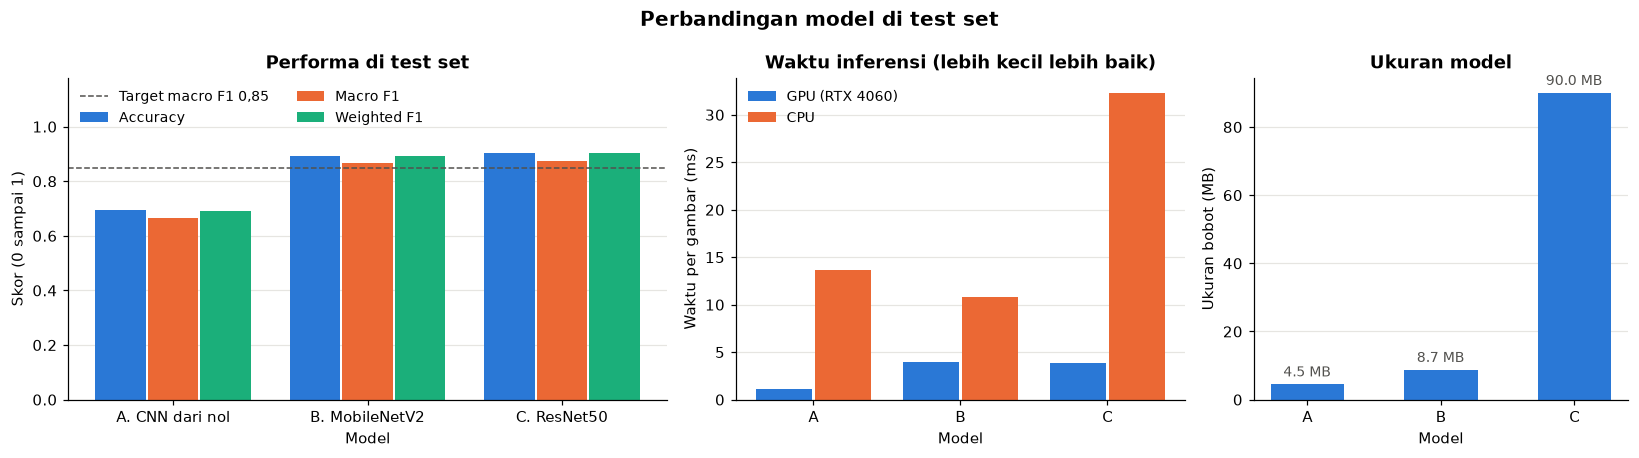

Disimpan: outputs/model_comparison.json dan outputs/model_comparison.png


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1.2, 1]})
labels = [f"{k}. {names[k]}" for k in test_results]
x = np.arange(len(labels))

# Panel 1: metrik performa
metrics = [("accuracy", "Accuracy", BLUE), ("macro_f1", "Macro F1", ORANGE), ("weighted_f1", "Weighted F1", GREEN_AQUA)]
w = 0.26
for i, (m, label, color) in enumerate(metrics):
    axes[0].bar(x + (i - 1) * (w + 0.01), [test_results[k][m] for k in test_results], w, color=color, label=label)
axes[0].axhline(0.85, color=MUTED, linestyle="--", linewidth=1, label="Target macro F1 0,85")
axes[0].set_xticks(x, labels)
axes[0].set_ylim(0, 1.18)
axes[0].set_ylabel("Skor (0 sampai 1)")
axes[0].set_xlabel("Model")
axes[0].set_title("Performa di test set")
axes[0].legend(frameon=False, loc="upper left", ncol=2, fontsize=9)

# Panel 2: waktu inferensi GPU vs CPU
w = 0.38
axes[1].bar(x - w / 2 - 0.01, [test_results[k]["gpu_ms"] for k in test_results], w, color=BLUE, label="GPU (RTX 4060)")
axes[1].bar(x + w / 2 + 0.01, [test_results[k]["cpu_ms"] for k in test_results], w, color=ORANGE, label="CPU")
axes[1].set_xticks(x, [k for k in test_results])
axes[1].set_ylabel("Waktu per gambar (ms)")
axes[1].set_xlabel("Model")
axes[1].set_title("Waktu inferensi (lebih kecil lebih baik)")
axes[1].legend(frameon=False, loc="upper left", fontsize=9)

# Panel 3: ukuran file
bars = axes[2].bar(x, [test_results[k]["size_mb"] for k in test_results], 0.55, color=BLUE)
axes[2].bar_label(bars, fmt="%.1f MB", padding=3, color=MUTED, fontsize=9)
axes[2].set_xticks(x, [k for k in test_results])
axes[2].set_ylabel("Ukuran bobot (MB)")
axes[2].set_xlabel("Model")
axes[2].set_title("Ukuran model")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.suptitle("Perbandingan model di test set", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

comparison_payload = {
    "split": "test",
    "n_test_images": int(len(test_preds["A"]["y_true"])),
    "selected_model": training_info["selected"],
    "models": {
        k: {**test_results[k], "val_macro_f1": training_info["experiments"][k]["summary"]["val_macro_f1"]}
        for k in test_results
    },
}
(OUTPUT_DIR / "model_comparison.json").write_text(json.dumps(comparison_payload, indent=2), encoding="utf-8")
print("Disimpan: outputs/model_comparison.json dan outputs/model_comparison.png")

Di test set, kedua model transfer learning tetap unggul jauh: MobileNetV2 mencapai accuracy 0,892 dan macro F1 0,868, ResNet50 mencapai 0,905 dan 0,875, sedangkan CNN dari nol hanya 0,694 dan 0,666. Angka test sedikit lebih rendah dari validation (macro F1 MobileNetV2 turun dari 0,881 ke 0,868). Ini wajar karena validation ikut dipakai untuk memilih checkpoint, sehingga sedikit optimistis.

**Jawaban pertanyaan 2 (keuntungan transfer learning):** transfer learning menaikkan macro F1 sekitar **20 poin** (0,666 menjadi 0,868 untuk MobileNetV2). Proporsi gambar yang salah ditebak turun dari sekitar 31% menjadi 11%, hampir 3 kali lebih sedikit, dengan waktu training yang lebih singkat. Menariknya, CNN dari nol justru lebih lambat di CPU daripada MobileNetV2 walaupun parameternya lebih sedikit, karena konvolusinya bekerja di resolusi penuh. MobileNetV2 memakai *depthwise separable convolution* yang dirancang supaya efisien.

ResNet50 unggul tipis di test (accuracy +1,3 poin atau sekitar 5 gambar, macro F1 +0,006). Keputusan memilih MobileNetV2 dibuat berdasarkan validation dan **tidak diubah** setelah melihat hasil test, karena mengubahnya sama dengan memakai test set untuk memilih model. Selisihnya pun masih di dalam toleransi 0,02 yang sudah ditetapkan sebelumnya.

### 5.2 Analisis model terpilih per kelas

Angka rata-rata bisa menyembunyikan kelas yang lemah. Di sini kita lihat performa model terpilih untuk setiap kelas:
- **Precision:** dari semua gambar yang ditebak sebagai kelas X, berapa persen yang benar-benar X.
- **Recall:** dari semua gambar kelas X, berapa persen yang berhasil dikenali.
- **F1:** gabungan keduanya.

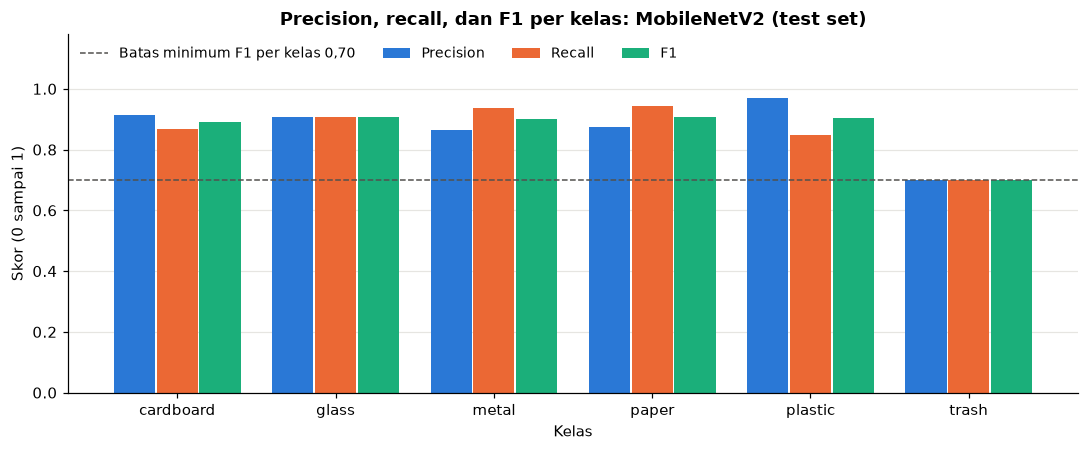

,precision,recall,f1-score,support
cardboard,0.914,0.869,0.891,61
glass,0.907,0.907,0.907,75
metal,0.866,0.935,0.899,62
paper,0.875,0.944,0.908,89
plastic,0.968,0.847,0.904,72
trash,0.700,0.700,0.700,20


In [25]:
best_key = training_info["selected"]["key"]
best_model = eval_models[best_key]
bp = test_preds[best_key]
report = per_class_report(bp["y_true"], bp["y_pred"], classes)
report_df = pd.DataFrame(report).T.loc[classes, ["precision", "recall", "f1-score", "support"]]
report_df["support"] = report_df["support"].astype(int)

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(classes))
w = 0.26
for i, (m, label, color) in enumerate([("precision", "Precision", BLUE), ("recall", "Recall", ORANGE), ("f1-score", "F1", GREEN_AQUA)]):
    ax.bar(x + (i - 1) * (w + 0.01), report_df[m], w, color=color, label=label)
ax.axhline(0.70, color=MUTED, linestyle="--", linewidth=1, label="Batas minimum F1 per kelas 0,70")
ax.set_xticks(x, classes)
ax.set_ylim(0, 1.18)
ax.set_xlabel("Kelas")
ax.set_ylabel("Skor (0 sampai 1)")
ax.set_title(f"Precision, recall, dan F1 per kelas: {names[best_key]} (test set)")
ax.legend(frameon=False, loc="upper left", ncol=4, fontsize=9)
ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "per_class_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

(OUTPUT_DIR / "per_class_metrics.json").write_text(
    json.dumps({"model": names[best_key], "split": "test", "report": report}, indent=2), encoding="utf-8"
)
report_df.round(3)

Lima kelas utama punya F1 antara 0,89 dan 0,91. Plastic punya precision tertinggi (0,97) tetapi recall 0,85: kalau model menjawab "plastik", jawabannya hampir selalu benar, tetapi sebagian plastik "lolos" ke kelas lain. Trash adalah kelas terlemah dengan F1 **0,70**, tepat di batas minimum. Test set hanya berisi 20 gambar trash, sehingga satu gambar saja sudah menggeser recall sebesar 5 poin. Angka trash perlu dibaca dengan hati-hati.

### 5.3 Confusion matrix

Confusion matrix menunjukkan ke mana saja setiap kelas "lari" saat salah ditebak. Baris adalah label asli, kolom adalah prediksi, dan diagonal adalah prediksi yang benar. Versi ternormalisasi membagi setiap baris dengan jumlah gambar kelas tersebut, sehingga kelas kecil seperti trash bisa dibandingkan secara adil.

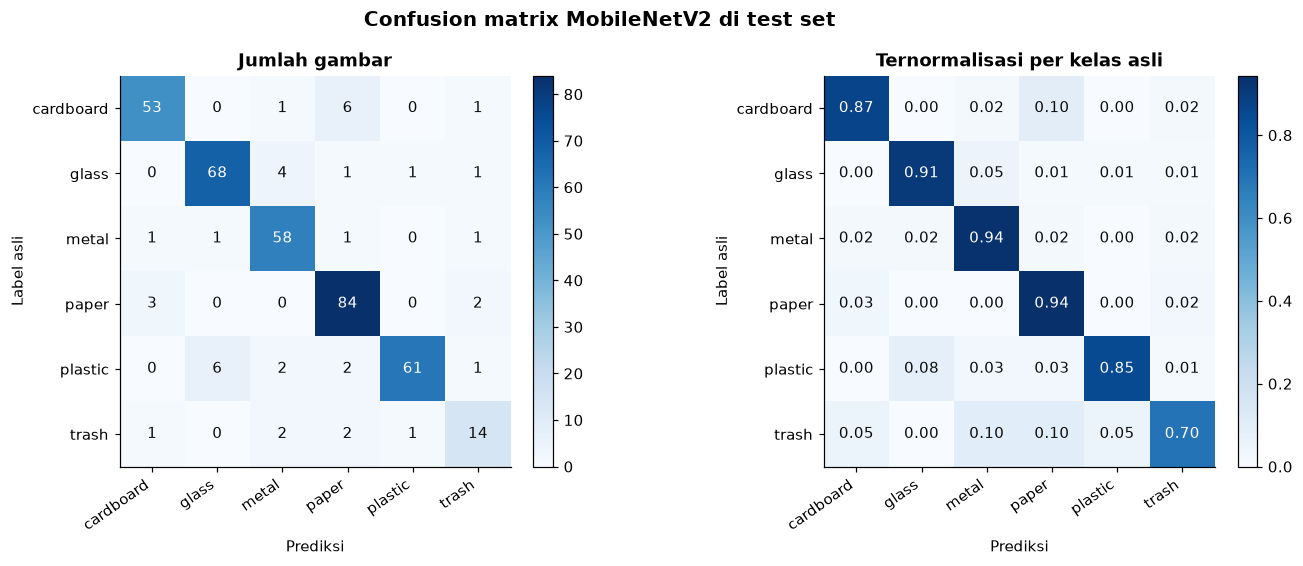

label asli,ditebak sebagai,jumlah,persen dari kelas asli
cardboard,paper,6,9.8%
plastic,glass,6,8.3%
glass,metal,4,5.3%
paper,cardboard,3,3.4%
trash,metal,2,10.0%
trash,paper,2,10.0%


In [26]:
cm = confusion_matrix(bp["y_true"], bp["y_pred"], labels=range(len(classes)))
fig = plot_confusion_matrices(cm, classes, f"Confusion matrix {names[best_key]} di test set")
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

confusions = top_confusions(cm, classes, k=6)
(OUTPUT_DIR / "confusion_matrix.json").write_text(json.dumps({
    "model": names[best_key], "split": "test", "classes": classes,
    "matrix": cm.tolist(), "normalized": (cm / cm.sum(axis=1, keepdims=True)).round(4).tolist(),
    "top_confusions": confusions,
}, indent=2), encoding="utf-8")

pd.DataFrame(confusions).rename(columns={
    "true": "label asli", "pred": "ditebak sebagai", "count": "jumlah", "rate_of_true": "persen dari kelas asli",
}).style.format({"persen dari kelas asli": "{:.1%}"}).hide(axis="index")

**Jawaban pertanyaan 3 (kelas yang paling sering tertukar):**
1. **cardboard ke paper (6 gambar, 9,8% dari cardboard) dan paper ke cardboard (3 gambar).** Kardus tipis berwarna putih atau abu-abu dan kotak kemasan bercetak (kotak sepatu, kotak produk) permukaannya mirip kertas tebal. Ciri pembeda utama kardus, yaitu lapisan bergelombang di bagian potongannya, sering tidak terlihat dari sudut foto.
2. **plastic ke glass (6 gambar, 8,3% dari plastic).** Botol dan wadah plastik bening sama-sama transparan dan memantulkan cahaya seperti kaca, apalagi botol plastik hijau yang mirip botol kaca.
3. **glass ke metal (4 gambar).** Dasar botol kaca gelap dengan cincin yang mengilap terlihat seperti logam, dan ada satu tutup toples logam yang dilabeli glass.
4. **Trash tersebar ke metal, paper, cardboard, dan plastic.** Trash bukan satu jenis material, melainkan campuran (bungkus snack beraluminium, sachet kertas, plastik), sehingga isinya memang mirip kelas lain.

Polanya konsisten: kesalahan terjadi antar material yang tampilan permukaannya mirip (transparan, datar, atau mengilap), bukan acak.

### 5.4 Error analysis: gambar yang salah ditebak

Melihat langsung gambar yang salah ditebak membantu memahami *kenapa* model salah, bukan hanya *berapa kali*. Gambar diurutkan dari confidence tertinggi, karena kesalahan yang "yakin" paling berbahaya di aplikasi nyata (aplikasi akan memberi saran yang salah dengan penuh percaya diri).

Salah ditebak: 41 dari 379 gambar (10.8%)
Median confidence prediksi benar: 0.99, prediksi salah: 0.71


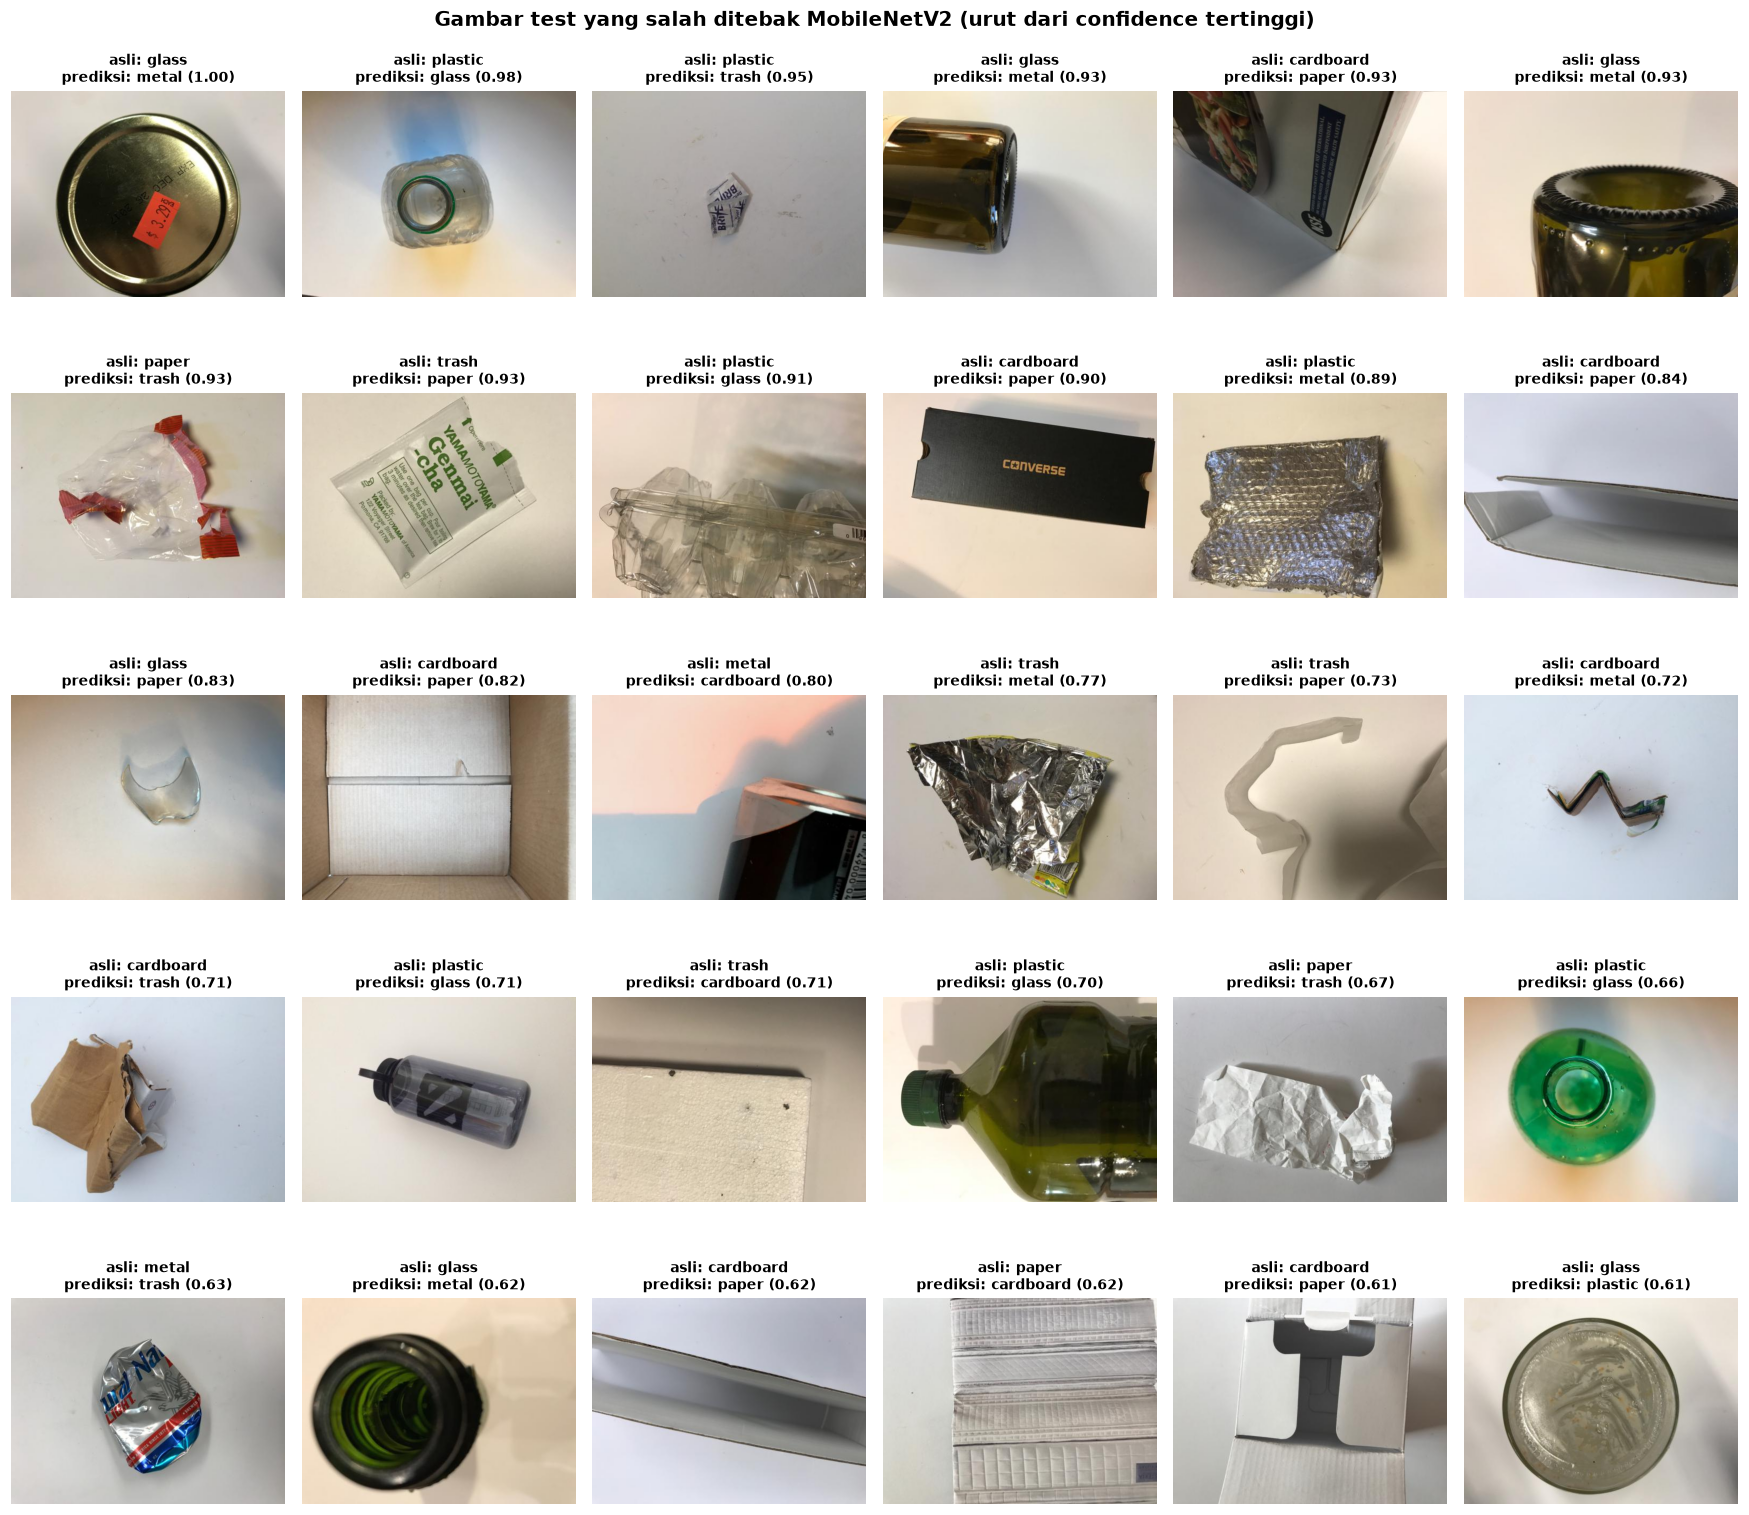

In [27]:
test_items = splits["test"]
confidence = bp["probs"].max(axis=1)
wrong_idx = np.where(bp["y_true"] != bp["y_pred"])[0]
wrong_idx = wrong_idx[np.argsort(-confidence[wrong_idx])]
print(f"Salah ditebak: {len(wrong_idx)} dari {len(test_items)} gambar ({len(wrong_idx) / len(test_items):.1%})")
print(f"Median confidence prediksi benar: {np.median(confidence[bp['y_true'] == bp['y_pred']]):.2f}, "
      f"prediksi salah: {np.median(confidence[wrong_idx]):.2f}")

n_cols = 6
n_show = min(len(wrong_idx), 30)
n_rows = int(np.ceil(n_show / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.9 * n_rows))
for ax in axes.flat:
    ax.axis("off")
for ax, idx in zip(axes.flat, wrong_idx[:n_show]):
    rel, _ = test_items[idx]
    ax.imshow(Image.open(DATA_DIR / rel))
    ax.set_title(f"asli: {classes[bp['y_true'][idx]]}\nprediksi: {classes[bp['y_pred'][idx]]} ({confidence[idx]:.2f})", fontsize=9)
fig.suptitle(f"Gambar test yang salah ditebak {names[best_key]} (urut dari confidence tertinggi)", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "misclassified_examples.png", dpi=120, bbox_inches="tight")
plt.show()

Ada 41 kesalahan (10,8%). Median confidence prediksi yang salah adalah 0,71, jauh di bawah prediksi yang benar (0,99). Artinya sebagian besar kesalahan terjadi saat model ragu. Di aplikasi nyata, ambang confidence (misalnya di bawah 0,8 aplikasi menjawab "kurang yakin, coba foto ulang") bisa mencegah banyak saran yang salah.

Dari grid di atas, kesalahan bisa dikelompokkan menjadi lima jenis:
1. **Material transparan (plastic dan glass):** gelas plastik bening, kemasan plastik bening, serta botol plastik hijau dan botol minyak yang tampak seperti kaca.
2. **Kardus tipis vs kertas (cardboard dan paper):** kotak kemasan putih atau abu-abu, tutup kotak sepatu, dan bagian dalam kotak yang tidak memperlihatkan lapisan bergelombang.
3. **Permukaan mengilap atau beraluminium (ke atau dari metal):** dasar botol kaca gelap, bungkus foil, bubble wrap berlapis aluminium, dan kaleng penyok yang bercetak warna-warni.
4. **Objek kecil, terpotong, atau close-up:** potongan kertas kecil, lipatan kardus kecil, dan botol yang hanya terlihat sebagian, sehingga petunjuk bentuk objek hilang.
5. **Label yang ambigu atau diragukan:** misalnya tutup toples logam berlabel glass (prediksi metal justru masuk akal), kemasan plastik berlabel paper, dan sachet kertas berlabel trash. Kesalahan jenis ini lebih mencerminkan masalah label di dataset daripada kelemahan model.

### 5.5 Interpretability dengan Grad-CAM

**Grad-CAM** menunjukkan bagian gambar yang paling memengaruhi keputusan model. Caranya: melihat seberapa besar setiap area di layer konvolusi terakhir berkontribusi ke skor kelas yang diprediksi. Area merah berarti sangat berpengaruh, area biru berarti hampir tidak berpengaruh.

Ini penting untuk mengecek apakah model benar-benar belajar mengenali sampahnya, atau hanya "curang" dengan melihat background (kekhawatiran dari bagian 2). Untuk setiap kelas ditampilkan 2 prediksi benar dan 1 prediksi salah.

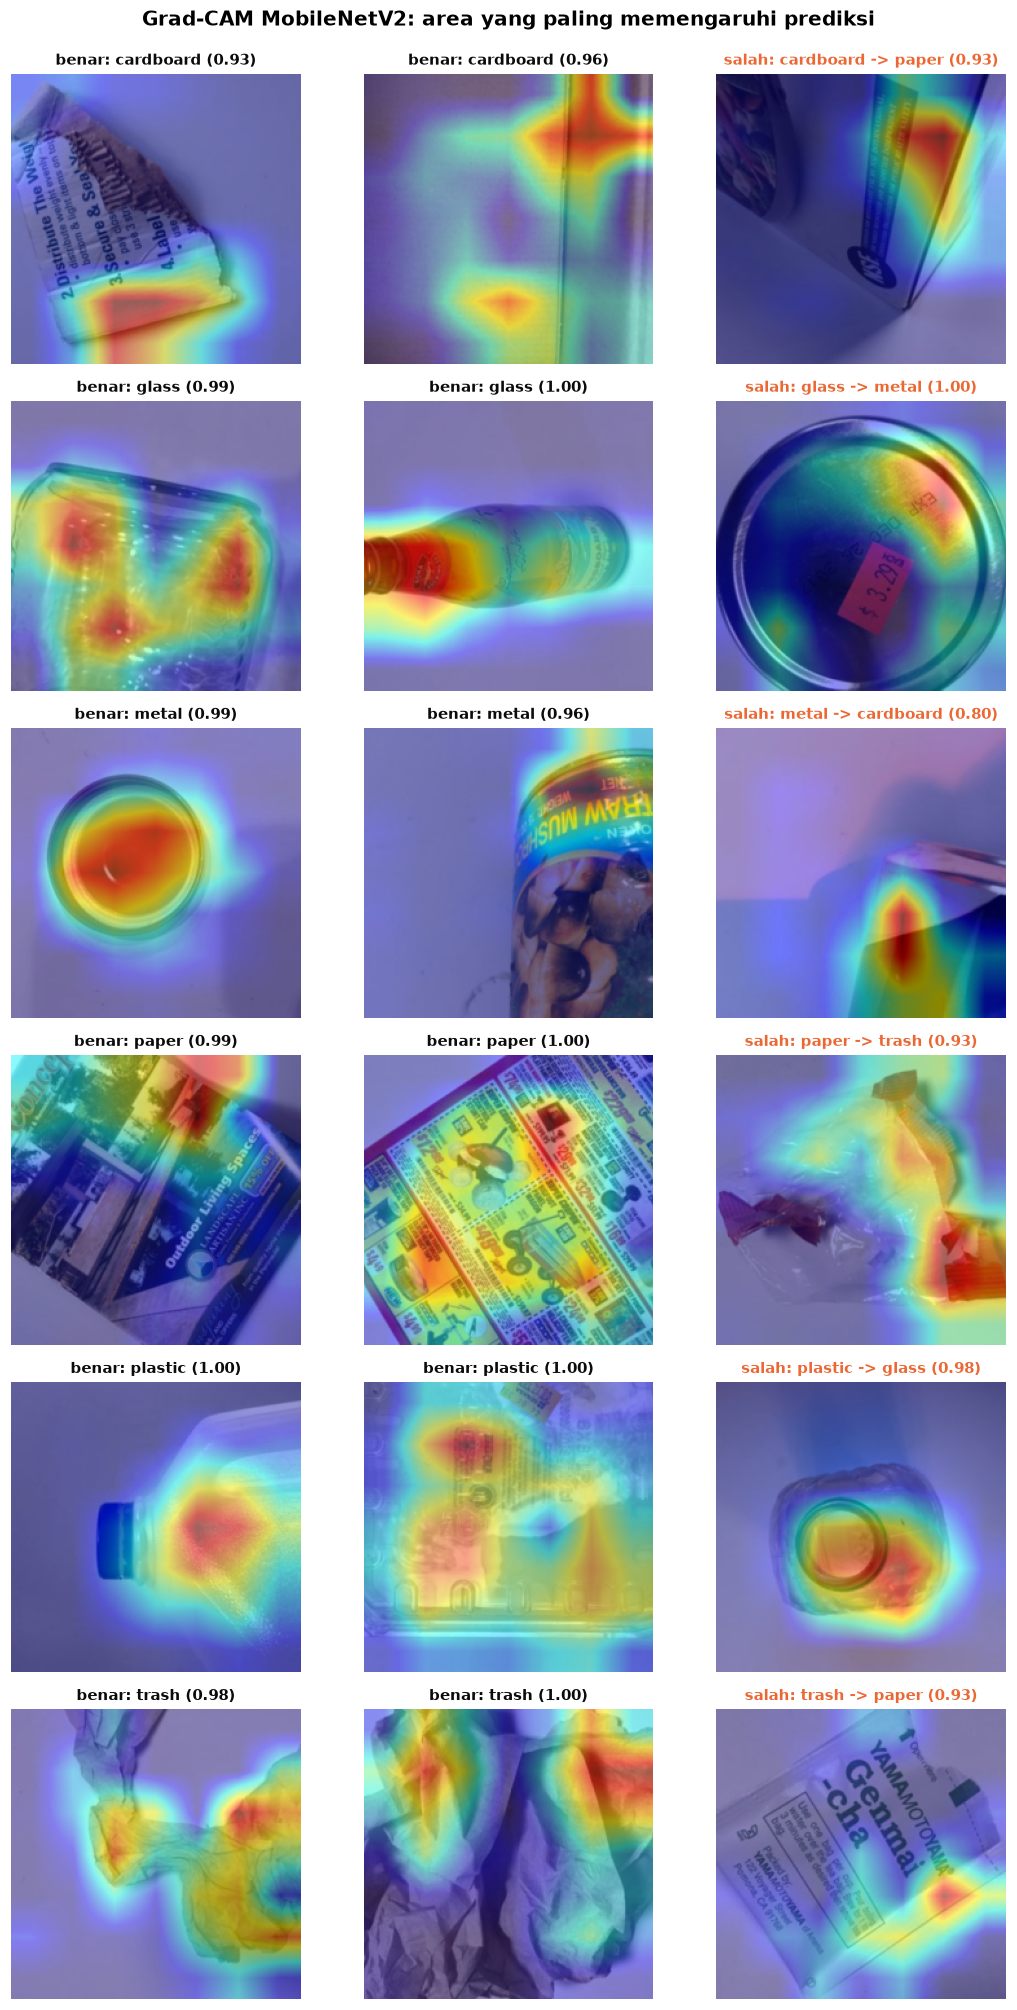

In [28]:
eval_tf = get_transforms(train=False)


def load_eval_tensor(rel):
    return eval_tf(Image.open(DATA_DIR / rel).convert("RGB"))


rng = np.random.default_rng(SEED)
panels = []
for c in range(len(classes)):
    correct = np.where((bp["y_true"] == c) & (bp["y_pred"] == c))[0]
    wrong = np.where((bp["y_true"] == c) & (bp["y_pred"] != c))[0]
    picks = [("benar", i) for i in rng.choice(correct, 2, replace=False)]
    if len(wrong):
        picks.append(("salah", wrong[np.argmax(confidence[wrong])]))
    panels.append(picks)

fig, axes = plt.subplots(len(classes), 3, figsize=(10, 3.1 * len(classes)))
for r, picks in enumerate(panels):
    tensors = torch.stack([load_eval_tensor(test_items[i][0]) for _, i in picks])
    heatmaps = compute_gradcam(best_model, tensors.to(device), [bp["y_pred"][i] for _, i in picks])
    for col in range(3):
        ax = axes[r, col]
        ax.axis("off")
        if col >= len(picks):
            ax.text(0.5, 0.5, "tidak ada\nprediksi salah", ha="center", va="center", color=MUTED)
            continue
        kind, i = picks[col]
        rgb = denormalize(tensors[col]).permute(1, 2, 0).numpy()
        ax.imshow(overlay_cam(rgb, heatmaps[col]))
        title = f"{kind}: {classes[bp['y_true'][i]]}"
        if kind == "salah":
            title += f" -> {classes[bp['y_pred'][i]]}"
        ax.set_title(f"{title} ({confidence[i]:.2f})", fontsize=10, color="#0b0b0b" if kind == "benar" else ORANGE)
fig.suptitle(f"Grad-CAM {names[best_key]}: area yang paling memengaruhi prediksi", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(FIG_DIR / "gradcam_examples.png", dpi=120, bbox_inches="tight")
plt.show()

Pada prediksi yang benar, heatmap umumnya jatuh di **objek sampah**: leher dan badan botol kaca, bagian tengah kaleng, badan botol plastik, dan lipatan bungkus trash. Background putih hampir selalu biru (tidak berpengaruh). Pada foto close-up kardus, model melihat tepi dan lipatan kardus, yang memang ciri khas kardus.

Pada prediksi yang salah, model tetap melihat objeknya, tetapi bagian yang dilihat menyesatkan. Pada cardboard yang ditebak paper, model fokus ke area tulisan tercetak (mirip kertas). Pada plastic yang ditebak glass, model fokus ke cincin mulut wadah yang bening. Pada glass yang ditebak metal, model melihat tutup logam, yang memang logam sehingga labelnya yang diragukan. Jadi kesalahan berasal dari kemiripan material, bukan karena model melihat background.

Untuk mengecek secara kuantitatif (bukan hanya dari beberapa contoh), kita hitung Grad-CAM untuk **seluruh** test set, lalu bandingkan rata-rata perhatian di bingkai tepi gambar (12,5% dari setiap sisi, area yang biasanya berisi background) dengan rata-rata di seluruh gambar. Rasio di bawah 1 berarti model lebih sedikit melihat tepi dibanding rata-rata, rasio di atas 1 berarti model justru banyak melihat tepi.

Median rasio perhatian tepi: prediksi benar 0.58, prediksi salah 0.62


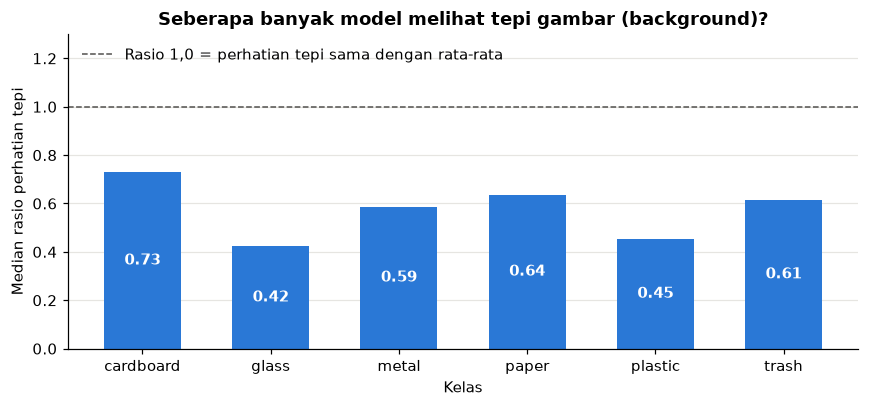

In [29]:
all_heatmaps = []
for start in range(0, len(test_items), 32):
    idx = range(start, min(start + 32, len(test_items)))
    batch = torch.stack([load_eval_tensor(test_items[i][0]) for i in idx]).to(device)
    all_heatmaps.append(compute_gradcam(best_model, batch, [bp["y_pred"][i] for i in idx]))
all_heatmaps = np.concatenate(all_heatmaps)
ratios = border_attention_ratio(all_heatmaps)

attention_df = pd.DataFrame({
    "kelas": [classes[t] for t in bp["y_true"]],
    "benar": bp["y_true"] == bp["y_pred"],
    "rasio_tepi": ratios,
})
by_class = attention_df.groupby("kelas")["rasio_tepi"].median().reindex(classes)
print(f"Median rasio perhatian tepi: prediksi benar {attention_df[attention_df.benar].rasio_tepi.median():.2f}, "
      f"prediksi salah {attention_df[~attention_df.benar].rasio_tepi.median():.2f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(classes, by_class.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.2f", label_type="center", color="white", fontweight="bold")
ax.axhline(1.0, color=MUTED, linestyle="--", linewidth=1, label="Rasio 1,0 = perhatian tepi sama dengan rata-rata")
ax.set_ylim(0, 1.3)
ax.set_xlabel("Kelas")
ax.set_ylabel("Median rasio perhatian tepi")
ax.set_title("Seberapa banyak model melihat tepi gambar (background)?")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Median rasio perhatian tepi di semua kelas berada di bawah 1 (0,42 sampai 0,73), baik untuk prediksi benar (0,58) maupun salah (0,62). Artinya model secara konsisten lebih banyak melihat bagian tengah gambar, tempat objek berada, daripada tepi yang berisi background. Cardboard punya rasio tertinggi (0,73) karena kardus sering memenuhi frame sampai ke tepi, sesuai dengan temuan warna di bagian 2.

Kesimpulannya, **tidak ada tanda model "curang" dengan memakai background**. Namun ini belum membuktikan model akan bekerja baik di background yang ramai, karena semua foto di dataset berlatar polos.

### 5.6 Uji ketahanan (robustness)

Foto di dunia nyata jarang sebaik foto di dataset: bisa gelap, buram karena tangan bergerak, atau miring. Di sini gambar test diberi gangguan buatan, lalu kita ukur seberapa besar akurasi turun. Semua gangguan bersifat deterministik (tanpa unsur acak), jadi hasilnya bisa diulang:
- **Gelap:** kecerahan dikurangi menjadi 60% dan 35%.
- **Blur:** Gaussian blur radius 2 (sedikit buram) dan 5 (sangat buram).
- **Rotasi:** diputar 30 derajat (sudut kosong diisi warna background) dan 90 derajat. Rotasi 30 derajat melebihi augmentasi saat training (maksimal 15 derajat).

Ketiga model diuji supaya terlihat apakah model yang lebih besar juga lebih tahan gangguan.

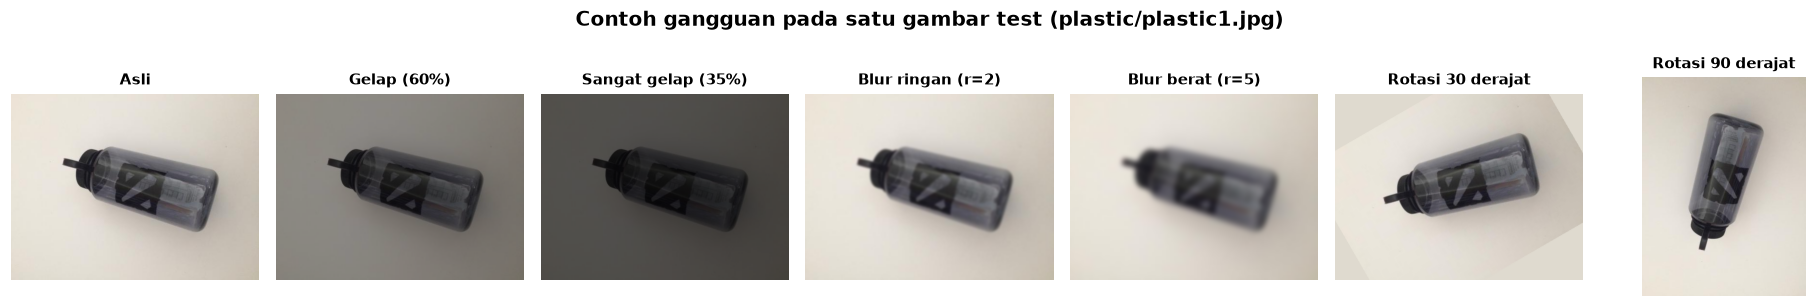

In [30]:
example_rel = test_items[int(np.where(bp["y_true"] == classes.index("plastic"))[0][0])][0]
perturb_fns = perturbations()
fig, axes = plt.subplots(1, len(perturb_fns), figsize=(17, 2.8))
base = Image.open(DATA_DIR / example_rel).convert("RGB")
for ax, (name, fn) in zip(axes, perturb_fns.items()):
    ax.imshow(fn(base))
    ax.set_title(name, fontsize=10)
    ax.axis("off")
fig.suptitle(f"Contoh gangguan pada satu gambar test ({example_rel})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [31]:
robust_rows = []
for name, fn in perturb_fns.items():
    y_true_p, preds_p = predict_many(eval_models, perturbed_loader(DATA_DIR, test_items, classes, fn), device)
    for key, y_pred_p in preds_p.items():
        robust_rows.append({"gangguan": name, "key": key, "model": names[key], **summary_metrics(y_true_p, y_pred_p)})
robust_df = pd.DataFrame(robust_rows)
baseline = robust_df[robust_df.gangguan == "Asli"].set_index("key")["accuracy"]
robust_df["turun_akurasi"] = robust_df.apply(lambda r: baseline[r["key"]] - r["accuracy"], axis=1)

(OUTPUT_DIR / "robustness.json").write_text(json.dumps({
    "split": "test",
    "note": "Gangguan deterministik diterapkan sebelum resize/center crop. turun_akurasi = akurasi asli - akurasi dengan gangguan.",
    "results": robust_df.to_dict(orient="records"),
}, indent=2), encoding="utf-8")

acc_table = robust_df.pivot(index="gangguan", columns="model", values="accuracy").reindex(list(perturb_fns))
drop_table = robust_df.pivot(index="gangguan", columns="model", values="turun_akurasi").reindex(list(perturb_fns))
acc_table = acc_table[[names[k] for k in eval_models]]
drop_table = drop_table[[names[k] for k in eval_models]]
pd.concat({"Accuracy": acc_table, "Turun (poin)": drop_table * 100}, axis=1).style.format("{:.3f}", subset="Accuracy").format("{:.1f}", subset="Turun (poin)")

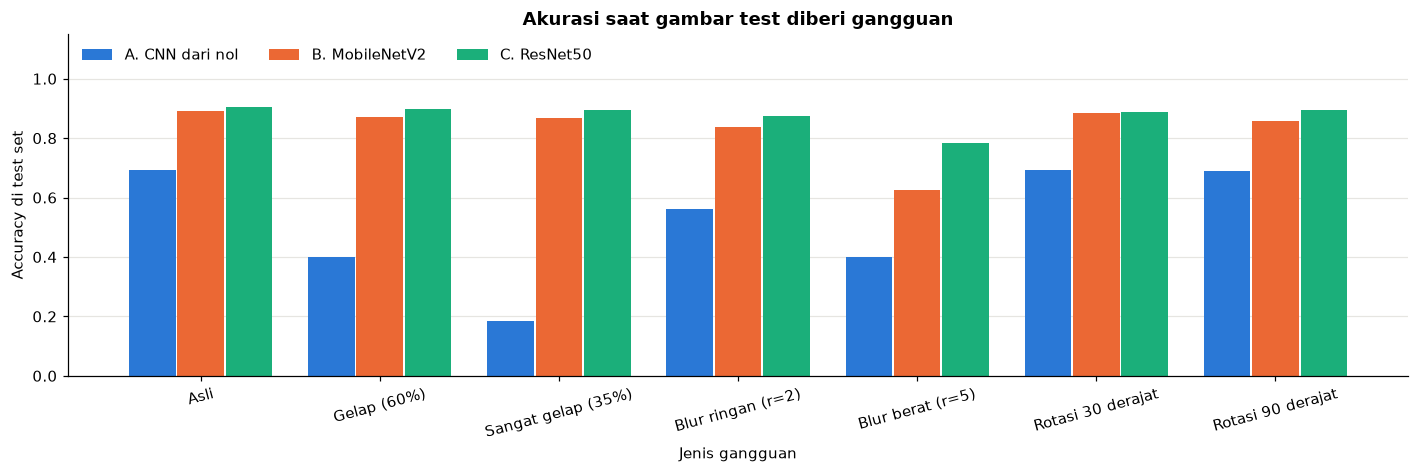

In [32]:
fig, ax = plt.subplots(figsize=(13, 4.4))
conds = list(perturb_fns)
x = np.arange(len(conds))
w = 0.26
for i, (key, color) in enumerate(zip(eval_models, [BLUE, ORANGE, GREEN_AQUA])):
    ax.bar(x + (i - 1) * (w + 0.01), acc_table[names[key]].values, w, color=color, label=f"{key}. {names[key]}")
ax.set_xticks(x, conds, rotation=15)
ax.set_ylim(0, 1.15)
ax.set_xlabel("Jenis gangguan")
ax.set_ylabel("Accuracy di test set")
ax.set_title("Akurasi saat gambar test diberi gangguan")
ax.legend(frameon=False, loc="upper left", ncol=3)
ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "robustness.png", dpi=150, bbox_inches="tight")
plt.show()

- **Gelap:** MobileNetV2 dan ResNet50 hampir tidak terpengaruh (turun sekitar 1 sampai 2,5 poin, bahkan pada kecerahan 35%). Sebaliknya, CNN dari nol **runtuh** (turun 29 dan 51 poin). Ini tanda model tersebut banyak mengandalkan kecerahan dan warna, bukan bentuk atau tekstur.
- **Blur:** titik lemah terbesar. Blur ringan menurunkan akurasi MobileNetV2 5,3 poin, tetapi blur berat menurunkannya **26,6 poin** (dari 0,892 ke 0,625). ResNet50 lebih tahan (turun 12,1 poin). Tekstur seperti serat kardus dan kilap kaca adalah petunjuk penting yang hilang saat gambar buram, dan augmentasi saat training tidak memasukkan blur.
- **Rotasi:** hampir tidak berpengaruh (turun di bawah 3,5 poin), karena sampah memang tidak punya orientasi tetap dan augmentasi sudah mencakup rotasi.

Pelajaran untuk dunia nyata: aplikasi perlu memastikan foto cukup tajam (misalnya meminta pengguna memotret ulang kalau gambar buram), dan versi berikutnya sebaiknya menambahkan augmentasi blur dan noise saat training. Model yang lebih besar (ResNet50) lebih tahan gangguan, jadi ini adalah trade-off nyata dengan ukuran model.

## 6. Kesimpulan

### Apakah kriteria sukses tercapai?
Tabel berikut dihitung langsung dari hasil test set model terpilih, bukan diisi manual.

In [33]:
best = test_results[best_key]
min_f1_class = min(classes, key=lambda c: report[c]["f1-score"])
criteria = pd.DataFrame([
    {"Kriteria": "Macro F1 di test set", "Target": "> 0,85", "Hasil": f"{best['macro_f1']:.3f}", "Tercapai": best["macro_f1"] > 0.85},
    {"Kriteria": "F1 per kelas terendah", "Target": ">= 0,70", "Hasil": f"{report[min_f1_class]['f1-score']:.3f} ({min_f1_class})",
     "Tercapai": report[min_f1_class]["f1-score"] >= 0.70},
    {"Kriteria": "Ukuran model", "Target": "< 30 MB", "Hasil": f"{best['size_mb']:.1f} MB", "Tercapai": best["size_mb"] < 30},
    {"Kriteria": "Waktu inferensi (CPU, proxy browser)", "Target": "< 1 detik", "Hasil": f"{best['cpu_ms']:.0f} ms", "Tercapai": best["cpu_ms"] < 1000},
])
criteria["Tercapai"] = criteria["Tercapai"].map({True: "Ya", False: "Belum"})
criteria.style.hide(axis="index")

Kriteria,Target,Hasil,Tercapai
Macro F1 di test set,"> 0,85",0.868,Ya
F1 per kelas terendah,">= 0,70",0.700 (trash),Ya
Ukuran model,< 30 MB,8.7 MB,Ya
"Waktu inferensi (CPU, proxy browser)",< 1 detik,11 ms,Ya


Semua kriteria tercapai, dengan dua catatan: F1 trash (0,70) tepat di batas minimum, dan waktu inferensi di browser baru akan diukur langsung di tahap Deployment (angka di atas adalah waktu di CPU laptop sebagai perkiraan).

### Jawaban pertanyaan bisnis
1. **Seberapa akurat model dengan data yang terbatas?** Dengan sekitar 1.760 gambar training, MobileNetV2 mencapai **accuracy 0,892 dan macro F1 0,868** di test set. Artinya sekitar 9 dari 10 foto sampah dikenali dengan benar, dengan catatan foto diambil dalam kondisi seperti dataset (latar polos, pencahayaan cukup, tidak buram).
2. **Seberapa besar keuntungan transfer learning?** Sangat besar: macro F1 naik sekitar 20 poin (0,666 menjadi 0,868) dan jumlah kesalahan turun hampir 3 kali, dengan waktu training yang lebih singkat. CNN dari nol juga jauh lebih rapuh terhadap perubahan pencahayaan.
3. **Kelas mana yang paling sering tertukar, dan kenapa?** Cardboard dan paper (kardus tipis dan kertas tebal permukaannya mirip), serta plastic yang ditebak glass (sama-sama transparan dan mengilap). Kelas trash paling lemah karena isinya campuran berbagai material dan datanya paling sedikit.
4. **Model mana yang paling cocok untuk aplikasi nyata?** **MobileNetV2.** Performanya setara ResNet50 (selisih macro F1 kurang dari 0,01) dengan ukuran 10 kali lebih kecil (8,7 MB vs 90 MB) dan inferensi di CPU beberapa kali lebih cepat. Di GPU keduanya sama-sama hanya beberapa milidetik, tetapi browser pengguna umumnya menjalankan model di CPU. ResNet50 hanya unggul jelas dalam ketahanan terhadap blur berat.

### Keterbatasan
- **Dataset kecil** (2.521 gambar), terutama kelas trash (137 gambar, hanya 20 di test set), sehingga angka per kelas punya ketidakpastian yang cukup besar.
- **Foto studio dengan background seragam** dan pencahayaan dalam ruangan. Akurasi di tempat sampah atau TPS sungguhan kemungkinan lebih rendah.
- **Hanya satu objek per gambar.** Model belum bisa menangani tumpukan sampah campuran.
- **Belum diuji di foto nyata**, apalagi dari kondisi Indonesia (kemasan lokal, sampah kotor atau basah).
- **Rentan terhadap foto buram**, seperti terlihat pada uji ketahanan.
- **Beberapa label di dataset diragukan**, sehingga sebagian kesalahan sebenarnya berasal dari label.

### Ide pengembangan
1. **Menambah data foto nyata** dari lingkungan Indonesia (TPS, bank sampah, rumah tangga) dengan background ramai dan kondisi kotor.
2. **Augmentasi yang lebih kaya**, seperti blur, noise, dan penggantian background, supaya model lebih tahan kondisi nyata.
3. **Object detection** (misalnya YOLO) untuk mengenali banyak sampah sekaligus dalam satu foto, lengkap dengan lokasinya.
4. **Menambah kelas** sampah organik, B3 (baterai, lampu, obat), dan elektronik, yang penting dalam pengelolaan sampah di Indonesia.
5. **Ambang confidence di aplikasi:** kalau model ragu (misalnya confidence di bawah 0,8), aplikasi meminta foto ulang atau menampilkan dua kemungkinan teratas.
6. **Membersihkan label** yang ambigu dan menambah data untuk kelas trash.

Tahap berikutnya adalah **Deployment**: mengekspor MobileNetV2 ke format ONNX dan menjalankannya di website demo.

## 7. Deployment

Tujuan akhirnya adalah website demo yang menjalankan model **langsung di browser pengguna**, tanpa server. Keuntungannya: gratis di-hosting (GitHub Pages), foto pengguna tidak pernah dikirim ke mana pun (privasi terjaga), dan tetap bisa dipakai walaupun banyak pengguna sekaligus.

Caranya:
1. Model PyTorch di-export ke format **ONNX** (Open Neural Network Exchange), format standar yang bisa dijalankan di banyak platform.
2. Di browser, model dijalankan dengan **onnxruntime-web** (WebAssembly atau WebGPU).
3. Preprocessing di browser harus **sama persis** dengan saat training. Kalau berbeda (misalnya ukuran crop atau normalisasi), akurasi bisa turun drastis walaupun modelnya sama.

**Kenapa opset 18?** Opset adalah versi kumpulan operator ONNX. Exporter PyTorch terbaru (`dynamo=True`) menghasilkan opset 18, yang sudah didukung onnxruntime-web. Input dibuat tetap `1 x 3 x 224 x 224` (tanpa dynamic batch) karena website hanya memproses satu foto setiap kali, dan bentuk input yang tetap lebih sederhana untuk dioptimasi.

### 7.1 Export model terpilih ke ONNX

In [34]:
from src.deploy import (
    export_onnx, onnx_info, onnx_logits, onnx_session, preprocess_from_config,
    preprocessing_config, quantize_dynamic_int8, save_samples, annotate_samples,
)

MODELS_DIR = Path("models")
ONNX_PATH = MODELS_DIR / "garbage_classifier.onnx"

deploy_key = training_info["selected"]["key"]
deploy_model = builders[deploy_key](num_classes=len(classes))
deploy_model.load_state_dict(torch.load(training_info["selected"]["checkpoint"], map_location="cpu", weights_only=True))
deploy_model.eval()

export_onnx(deploy_model, ONNX_PATH, opset=18)
info = onnx_info(ONNX_PATH)
session = onnx_session(ONNX_PATH)
print(f"Model      : {names[deploy_key]}")
print(f"File       : {ONNX_PATH} ({info['size_mb']:.2f} MB)")
print(f"Opset      : {info['opset']}")
print(f"Operator   : {', '.join(info['operators'])}")
print(f"Input      : {session.get_inputs()[0].name} {session.get_inputs()[0].shape} {session.get_inputs()[0].type}")
print(f"Output     : {session.get_outputs()[0].name} {session.get_outputs()[0].shape}")

Model      : MobileNetV2
File       : models\garbage_classifier.onnx (8.71 MB)
Opset      : 18
Operator   : Add, Clip, Conv, Gemm, ReduceMean, Reshape
Input      : input [1, 3, 224, 224] tensor(float)
Output     : logits [1, 6]


Model berhasil di-export ke satu file ONNX berukuran 8,71 MB dengan opset 18. Grafnya hanya memakai 6 jenis operator standar: `Conv` (konvolusi), `Clip` (aktivasi ReLU6 khas MobileNetV2), `Add` (skip connection), `ReduceMean` (global average pooling), `Reshape`, dan `Gemm` (layer classifier). Semuanya didukung onnxruntime-web, jadi tidak ada operator eksotis yang berisiko gagal di browser.

### 7.2 Verifikasi: PyTorch vs ONNX Runtime

Export bisa saja mengubah perilaku model tanpa error (misalnya operator yang diterjemahkan berbeda). Karena itu, 20 gambar test dijalankan di PyTorch dan di ONNX Runtime, lalu dibandingkan prediksi dan nilai outputnya. Keduanya memakai float32 di CPU, sehingga selisihnya hanya berasal dari urutan perhitungan (idealnya sekitar 1e-5 atau lebih kecil).

In [35]:
rng = np.random.default_rng(SEED)
verify_idx = sorted(rng.choice(len(test_items), 20, replace=False))
verify_batch = torch.stack([load_eval_tensor(test_items[i][0]) for i in verify_idx])

with torch.no_grad():
    torch_logits = deploy_model(verify_batch).numpy()
ort_logits = onnx_logits(session, verify_batch.numpy())
abs_diff = np.abs(torch_logits - ort_logits)

verify_df = pd.DataFrame({
    "gambar": [test_items[i][0] for i in verify_idx],
    "label asli": [test_items[i][1] for i in verify_idx],
    "prediksi PyTorch": [classes[j] for j in torch_logits.argmax(1)],
    "prediksi ONNX": [classes[j] for j in ort_logits.argmax(1)],
    "selisih logit maks": abs_diff.max(axis=1),
})
verify_df["sama"] = verify_df["prediksi PyTorch"] == verify_df["prediksi ONNX"]
print(f"Prediksi sama : {verify_df['sama'].sum()} dari {len(verify_df)} gambar")
print(f"Selisih logit : maksimum {abs_diff.max():.2e}, rata-rata {abs_diff.mean():.2e}")
verify_df.style.format({"selisih logit maks": "{:.2e}"}).hide(axis="index")

Prediksi sama : 20 dari 20 gambar
Selisih logit : maksimum 1.43e-05, rata-rata 4.07e-06


gambar,label asli,prediksi PyTorch,prediksi ONNX,selisih logit maks,sama
cardboard/cardboard293.jpg,cardboard,cardboard,cardboard,9.06e-06,True
cardboard/cardboard294.jpg,cardboard,paper,paper,1.43e-05,True
cardboard/cardboard302.jpg,cardboard,cardboard,cardboard,7.63e-06,True
cardboard/cardboard382.jpg,cardboard,cardboard,cardboard,5.72e-06,True
glass/glass186.jpg,glass,metal,metal,7.15e-06,True
metal/metal222.jpg,metal,metal,metal,3.81e-06,True
metal/metal235.jpg,metal,metal,metal,6.68e-06,True
metal/metal300.jpg,metal,metal,metal,4.77e-06,True
metal/metal74.jpg,metal,metal,metal,2.86e-06,True
metal/metal89.jpg,metal,metal,metal,1.43e-05,True


Ke-20 gambar menghasilkan prediksi yang **sama persis** di PyTorch dan ONNX, dengan selisih logit maksimum 1,4e-5 (rata-rata sekitar 4e-6). Selisih sekecil ini hanya berasal dari urutan perhitungan floating point dan terlalu kecil untuk mengubah prediksi. Beberapa gambar memang salah ditebak (misalnya cardboard yang ditebak paper), tetapi kesalahannya sama di kedua versi, dan itulah yang ingin dibuktikan: ONNX adalah salinan setia model PyTorch.

Sebagai pemeriksaan tambahan, seluruh test set juga dijalankan lewat ONNX. Ini bukan untuk memilih model (keputusan sudah final), tetapi untuk memastikan file yang akan dipakai website memberi akurasi yang sama dengan model PyTorch.

In [36]:
test_batch = np.stack([load_eval_tensor(rel).numpy() for rel, _ in test_items])
test_labels = np.array([classes.index(c) for _, c in test_items])
with torch.no_grad():
    torch_test_pred = torch.cat([deploy_model(torch.from_numpy(test_batch[i:i + 64])).argmax(1)
                                 for i in range(0, len(test_batch), 64)]).numpy()
onnx_test_pred = onnx_logits(session, test_batch).argmax(1)
print(f"Accuracy test PyTorch (float32): {(torch_test_pred == test_labels).mean():.4f}")
print(f"Accuracy test ONNX    (float32): {(onnx_test_pred == test_labels).mean():.4f}")
print(f"Prediksi berbeda antara keduanya: {(torch_test_pred != onnx_test_pred).sum()} dari {len(test_labels)} gambar")

Accuracy test PyTorch (float32): 0.8918
Accuracy test ONNX    (float32): 0.8918
Prediksi berbeda antara keduanya: 0 dari 379 gambar


Di seluruh 379 gambar test, accuracy ONNX dan PyTorch sama-sama 0,8918, dan tidak ada satu pun prediksi yang berbeda. Angka ini juga sama dengan hasil evaluasi di bagian 5 (0,892), sehingga file ONNX aman dipakai website tanpa kehilangan akurasi.

### 7.3 Ukuran file dan quantization

Aturannya: kalau file ONNX lebih dari 20 MB, kita coba **dynamic quantization int8**, yaitu menyimpan bobot sebagai bilangan bulat 8-bit (bukan float 32-bit) sehingga file sekitar 4 kali lebih kecil, dengan risiko akurasi turun.

In [37]:
SIZE_LIMIT_MB = 20
size_mb = ONNX_PATH.stat().st_size / 1024**2
print(f"Ukuran ONNX float32: {size_mb:.2f} MB (batas {SIZE_LIMIT_MB} MB)")
if size_mb > SIZE_LIMIT_MB:
    print("Lebih dari batas: quantization int8 wajib dicoba sebelum memilih file untuk web.")
else:
    print("Di bawah batas: file float32 dipakai untuk web, quantization tidak wajib.")

# Perbandingan int8 tetap dihitung sebagai referensi, memakai VALIDATION set (test set tidak dipakai untuk keputusan)
INT8_PATH = CKPT_DIR / "garbage_classifier_int8.onnx"
quantize_dynamic_int8(ONNX_PATH, INT8_PATH)
int8_info = onnx_info(INT8_PATH)
val_items = splits["val"]
val_batch = np.stack([load_eval_tensor(rel).numpy() for rel, _ in val_items])
val_labels = np.array([classes.index(c) for _, c in val_items])
fp32_pred = onnx_logits(session, val_batch).argmax(1)
int8_pred = onnx_logits(onnx_session(INT8_PATH), val_batch).argmax(1)

quant_df = pd.DataFrame([
    {"versi": "float32", "ukuran (MB)": size_mb, "val accuracy": (fp32_pred == val_labels).mean(),
     "val macro F1": macro_f1(val_labels, fp32_pred), "operator khusus": "-"},
    {"versi": "int8 (dynamic)", "ukuran (MB)": int8_info["size_mb"], "val accuracy": (int8_pred == val_labels).mean(),
     "val macro F1": macro_f1(val_labels, int8_pred),
     "operator khusus": ", ".join(o for o in int8_info["operators"] if o not in info["operators"])},
])
quant_df.style.format({"ukuran (MB)": "{:.2f}", "val accuracy": "{:.4f}", "val macro F1": "{:.4f}"}).hide(axis="index")

Ukuran ONNX float32: 8.71 MB (batas 20 MB)
Di bawah batas: file float32 dipakai untuk web, quantization tidak wajib.


versi,ukuran (MB),val accuracy,val macro F1,operator khusus
float32,8.71,0.8836,0.8782,-
int8 (dynamic),2.34,0.8228,0.7893,"Cast, ConvInteger, DynamicQuantizeLinear, MatMulInteger, Mul"


File float32 hanya 8,71 MB, jauh di bawah batas 20 MB, jadi **versi float32 yang dipakai untuk web**. Perbandingan di atas menunjukkan keputusan ini juga masuk akal dari sisi kualitas: int8 memang 3,7 kali lebih kecil (2,34 MB), tetapi macro F1 validation turun dari 0,878 ke 0,789 (sekitar 9 poin). Selain itu int8 memakai operator khusus seperti `ConvInteger` dan `MatMulInteger` yang dukungannya di onnxruntime-web lebih terbatas (misalnya belum tersedia di backend WebGPU). Menghemat sekitar 6 MB unduhan tidak sepadan dengan turunnya akurasi.

Catatan kecil: accuracy validation float32 di sini (0,8836) berbeda 1 gambar dari bagian 4 (0,8862), karena bagian 4 memakai mixed precision (float16) saat evaluasi, sedangkan ONNX memakai float32 penuh.

### 7.4 Label dan konfigurasi preprocessing untuk browser

Dua file kecil disimpan di samping model:
- `models/labels.json`: urutan kelas. Output model hanya berupa 6 angka, dan urutan inilah yang menentukan angka ke-berapa milik kelas apa.
- `models/preprocessing.json`: semua parameter preprocessing (resize, crop, skala, mean, std, urutan channel), supaya kode JavaScript di browser tidak perlu "menebak".

Untuk membuktikan file konfigurasi ini cukup, gambar di-preprocess **hanya berdasarkan isi JSON** (resize dan crop manual dengan PIL, tanpa torchvision), lalu hasilnya dibandingkan dengan transform yang dipakai saat evaluasi.

In [38]:
prep_cfg = preprocessing_config()
(MODELS_DIR / "labels.json").write_text(json.dumps(classes, indent=2), encoding="utf-8")
(MODELS_DIR / "preprocessing.json").write_text(json.dumps(prep_cfg, indent=2, ensure_ascii=False), encoding="utf-8")

parity = []
for rel, _ in test_items[:50]:
    img = Image.open(DATA_DIR / rel)
    manual = preprocess_from_config(img, prep_cfg)
    parity.append(np.abs(manual - eval_tf(img).numpy()).max())
print("labels.json       :", json.loads((MODELS_DIR / "labels.json").read_text()))
print(f"Selisih preprocessing manual vs torchvision (50 gambar): maksimum {max(parity):.1e}")
print()
print((MODELS_DIR / "preprocessing.json").read_text(encoding="utf-8"))

labels.json       : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Selisih preprocessing manual vs torchvision (50 gambar): maksimum 7.2e-07

{
  "input_name": "input",
  "output_name": "logits",
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "layout": "NCHW",
  "color_order": "RGB",
  "resize": {
    "shorter_side": 256,
    "interpolation": "bilinear"
  },
  "center_crop": 224,
  "scale": 0.00392156862745098,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "output": "logits, terapkan softmax untuk mendapatkan probabilitas",
  "steps": [
    "Ubah gambar ke RGB",
    "Resize sisi pendek ke 256 px (bilinear), jaga rasio aspek",
    "Center crop 224 x 224",
    "Bagi nilai piksel dengan 255 (rentang 0 sampai 1)",
    "Normalisasi per channel: (x - mean) / std",
    "Susun sebagai float32 NCHW [1, 3, 224, 224]"
  ]
}


Preprocessing yang hanya mengikuti isi `preprocessing.json` menghasilkan tensor yang praktis identik dengan transform torchvision (selisih maksimum 7,2e-7, hanya pembulatan floating point). Artinya, file konfigurasi ini sudah cukup lengkap untuk ditiru di JavaScript.

Satu hal yang tetap perlu diperhatikan di browser: algoritma resize bawaan `canvas` bisa sedikit berbeda dari PIL. Untuk gambar yang jelas, perbedaan ini tidak mengubah prediksi, tetapi untuk gambar yang "di perbatasan" hasilnya bisa bergeser. Karena itu setiap contoh gambar demo disertai prediksi yang diharapkan (lihat bagian berikutnya), sebagai alat cek bahwa website berjalan dengan benar.

### 7.5 Contoh gambar untuk demo

Website menyediakan contoh gambar supaya pengunjung bisa langsung mencoba tanpa harus punya foto sampah. Diambil 2 gambar acak per kelas dari **test set** (belum pernah dilihat model saat training), diperkecil ke sisi terpanjang 400 px dalam format JPEG supaya ringan diunduh. Daftar file beserta labelnya disimpan di `samples.json`.

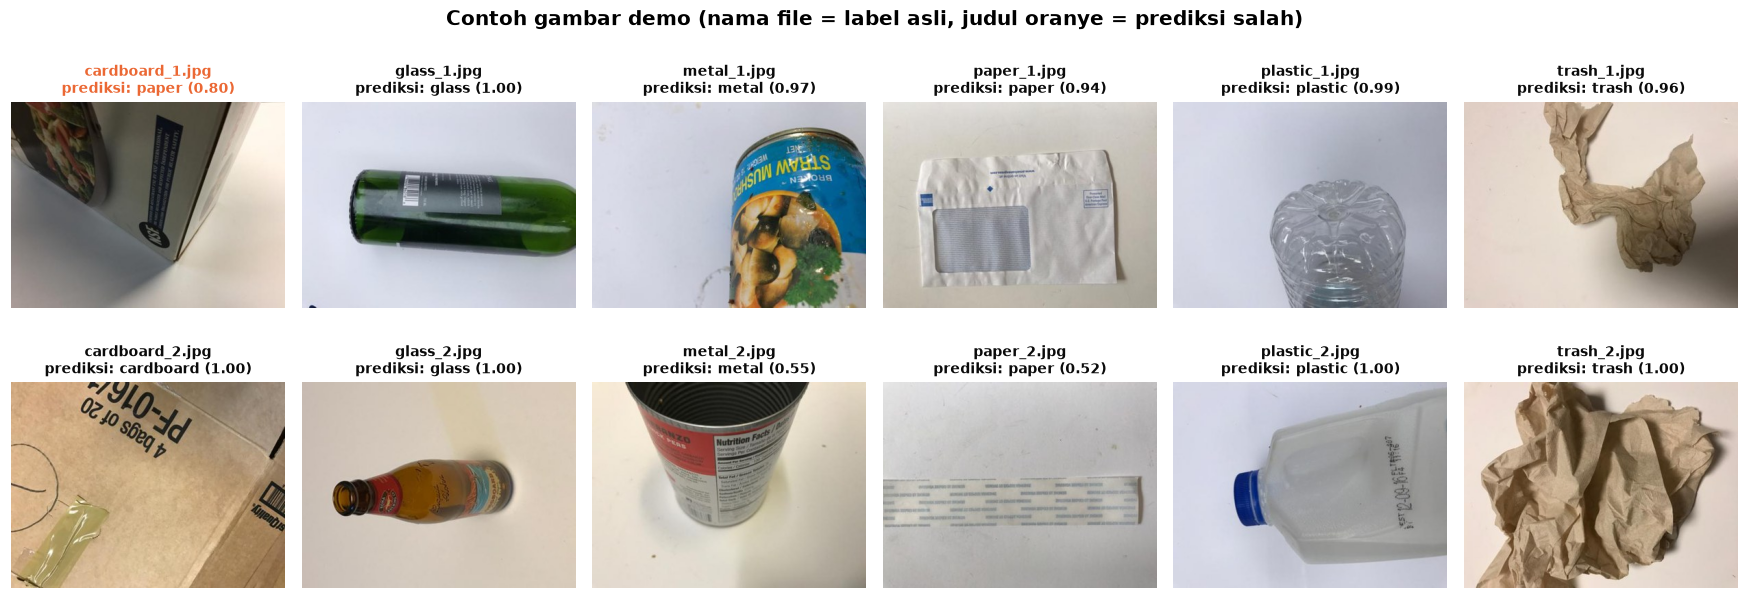

12 gambar, total 180 KB, prediksi benar 11 dari 12


In [39]:
SAMPLES_DIR = Path("site/assets/samples")
samples = save_samples(splits["test"], DATA_DIR, SAMPLES_DIR, classes, per_class=2, max_size=400, seed=SEED)
samples = annotate_samples(samples, SAMPLES_DIR, session, prep_cfg, classes)

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, s in zip(axes.T.flat, samples):
    ax.imshow(Image.open(SAMPLES_DIR / s["file"]))
    correct = s["expected_prediction"] == s["label"]
    ax.set_title(f"{s['file']}\nprediksi: {s['expected_prediction']} ({s['expected_confidence']:.2f})",
                 fontsize=9, color="#0b0b0b" if correct else ORANGE)
    ax.axis("off")
fig.suptitle("Contoh gambar demo (nama file = label asli, judul oranye = prediksi salah)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

total_kb = sum((SAMPLES_DIR / s["file"]).stat().st_size for s in samples) / 1024
n_correct = sum(s["expected_prediction"] == s["label"] for s in samples)
print(f"{len(samples)} gambar, total {total_kb:.0f} KB, prediksi benar {n_correct} dari {len(samples)}")

Ke-12 contoh (total sekitar 180 KB) dipilih acak dan **sengaja tidak dipilih-pilih**, supaya demo menggambarkan performa model apa adanya. Model menebak benar 11 dari 12:
- `cardboard_1.jpg` ditebak **paper**. Ini kasus kardus bercetak yang mirip kertas, sama seperti temuan di error analysis.
- `paper_2.jpg` ditebak benar, tetapi confidence-nya hanya sekitar 0,52 (ragu antara paper dan cardboard). Dari foto aslinya (512 x 384), model justru sedikit condong ke cardboard. Ini contoh nyata bahwa perubahan kecil (di sini karena resize ke 400 px) bisa menggeser prediksi gambar yang ambigu.

Prediksi dan confidence yang diharapkan untuk setiap file disimpan di `site/assets/samples/samples.json` (`expected_prediction`, `expected_confidence`). Kalau website menghasilkan angka yang sama untuk contoh-contoh ini, berarti preprocessing di browser sudah benar.

### 7.6 Menyiapkan folder website

Semua file yang dibutuhkan website disalin ke `site/` oleh script `scripts/build_site.py`. Script ini bisa dijalankan ulang kapan saja (misalnya setelah model dilatih ulang) dengan `python scripts/build_site.py`, tanpa harus membuka notebook.

In [40]:
import subprocess
import sys

result = subprocess.run([sys.executable, "scripts/build_site.py"], capture_output=True, text=True, encoding="utf-8")
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)

Model:
  models\garbage_classifier.onnx  ->  site\models\garbage_classifier.onnx  (8914 KB)
  models\labels.json  ->  site\models\labels.json  (0 KB)
  models\preprocessing.json  ->  site\models\preprocessing.json  (1 KB)
Data hasil analisis:
  outputs\confusion_matrix.json  ->  site\data\confusion_matrix.json  (2 KB)
  outputs\model_comparison.json  ->  site\data\model_comparison.json  (1 KB)
  outputs\per_class_metrics.json  ->  site\data\per_class_metrics.json  (1 KB)
  outputs\robustness.json  ->  site\data\robustness.json  (6 KB)
  outputs\training_history.json  ->  site\data\training_history.json  (27 KB)
  outputs\splits.json  ->  site\data\dataset_summary.json  (1 KB)
Gambar:
  outputs\confusion_matrix.png  ->  site\assets\img\confusion_matrix.jpg  (88 KB)
  outputs\gradcam_examples.png  ->  site\assets\img\gradcam_examples.jpg  (271 KB)
  outputs\misclassified_examples.png  ->  site\assets\img\misclassified_examples.jpg  (252 KB)
  outputs\model_comparison.png  ->  site\assets

Folder `site/` sekarang berisi semua bahan untuk website demo:
- `site/models/`: model ONNX (8,7 MB), `labels.json`, dan `preprocessing.json`.
- `site/data/`: hasil analisis dalam JSON (perbandingan model, metrik per kelas, confusion matrix, uji ketahanan, history training) untuk ditampilkan sebagai grafik di website. `splits.json` tidak disalin karena hanya daftar nama file yang tidak berguna bagi pengunjung.
- `site/assets/samples/`: 12 contoh gambar beserta `samples.json`.

**Ringkasan Deployment:** model terpilih (MobileNetV2) sudah tersedia sebagai file ONNX 8,7 MB yang terbukti menghasilkan prediksi identik dengan PyTorch, lengkap dengan label, konfigurasi preprocessing, dan contoh gambar. Langkah berikutnya adalah membuat halaman website (`site/index.html`) yang memuat model dengan onnxruntime-web, lalu mempublikasikannya lewat GitHub Pages dan menautkannya dari portofolio.